In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as ms
import sklearn
from scipy import stats
import glob
%matplotlib inline

print('Done Setup')

Done Setup


In [2]:
import pandas as pd
import glob

# List of your 20 company symbols or CSV filenames
tickers = ['NABIL', 'EBL', 'NIMB', 'ADBL', 'NTC', 'NLIC', 'LICN', 'AHPC', 
           'CHCL', 'SHPC', 'GBIME', 'SCB', 'HDL', 'STC', 'NFS', 'CIT', 
           'TAMOR', 'BBC', 'CZBIL', 'KBL']

# Option A: If your data is in separate CSV files named after the ticker (e.g., 'NABIL.csv')
dfs = []
for ticker in tickers:
    # Read individual CSV file
    df = pd.read_csv(f"{ticker}.csv")
    
    # Add a column to identify the company
    df['Company'] = ticker
    
    # Ensure Date column is in datetime format
    df['published_date'] = pd.to_datetime(df['published_date'])
    
    dfs.append(df)

# Combine all dataframes into a single master dataframe
master_df = pd.concat(dfs, ignore_index=True)

# Sort by Date and Company
master_df = master_df.sort_values(by=['published_date', 'Company']).reset_index(drop=True)
nepse_data = master_df.copy()
print(master_df.head())

  published_date    open    high     low   close  per_change  traded_quantity  \
0     1995-07-20  2220.0  2220.0  2220.0  2220.0         0.0            560.0   
1     1995-07-26  2220.0  2442.0  2442.0  2442.0         0.0            150.0   
2     1995-07-30  2442.0  2500.0  2500.0  2500.0         0.0            200.0   
3     1995-08-02  2500.0  2501.0  2501.0  2501.0         0.0             18.0   
4     1995-08-06  2501.0  2500.0  2500.0  2500.0         0.0             40.0   

   traded_amount  status Company  
0            0.0       0     BBC  
1            0.0       0     BBC  
2            0.0       0     BBC  
3            0.0       0     BBC  
4            0.0       0     BBC  


## Nan value cell

# A = data Acquistion 

In [3]:
nepse_data.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
published_date,58218,NaN,NaN,NaN,2019-06-15 22:49:54.125528,1995-07-20 00:00:00,2015-09-17 00:00:00,2019-12-23 00:00:00,2023-08-08 00:00:00,2026-10-16 00:00:00,NaN
open,58218.0,NaN,NaN,NaN,1183.818485,88.0,350.0,654.0,1530.0,13320.0,1325.655806
high,58218.0,NaN,NaN,NaN,1199.573595,0.0,355.0,660.0,1550.0,13780.0,1346.687986
low,58218.0,NaN,NaN,NaN,1166.756469,0.0,343.1,645.0,1508.75,12501.0,1304.156496
close,58218.0,NaN,NaN,NaN,1182.626655,0.0,349.0,653.0,1530.0,13317.0,1323.988782
per_change,58204.0,NaN,NaN,NaN,0.068831,-76.34,-0.95,0.0,0.81,330.48,2.860671
traded_quantity,58218.0,NaN,NaN,NaN,39687.112336,1.0,2411.25,10052.5,35104.0,3546853.0,101869.072506
traded_amount,58218.0,NaN,NaN,NaN,22934398.500616,0.0,2076569.5,7627664.05,21771461.7,1757930386.0,52315419.702124
status,58218.0,NaN,NaN,NaN,-0.086898,-1.0,-1.0,0.0,0.0,1.0,0.760985
Company,58218,20,CHCL,4479,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
nepse_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 58218 entries, 0 to 58217
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   published_date   58218 non-null  datetime64[us]
 1   open             58218 non-null  float64       
 2   high             58218 non-null  float64       
 3   low              58218 non-null  float64       
 4   close            58218 non-null  float64       
 5   per_change       58204 non-null  float64       
 6   traded_quantity  58218 non-null  float64       
 7   traded_amount    58218 non-null  float64       
 8   status           58218 non-null  int64         
 9   Company          58218 non-null  str           
dtypes: datetime64[us](1), float64(7), int64(1), str(1)
memory usage: 4.7 MB


## null values

In [5]:
nepse_data.isna().sum()

published_date      0
open                0
high                0
low                 0
close               0
per_change         14
traded_quantity     0
traded_amount       0
status              0
Company             0
dtype: int64

### null valeues discription
- per_change = NaN, meaning the company has just started

### null graph

<Axes: >

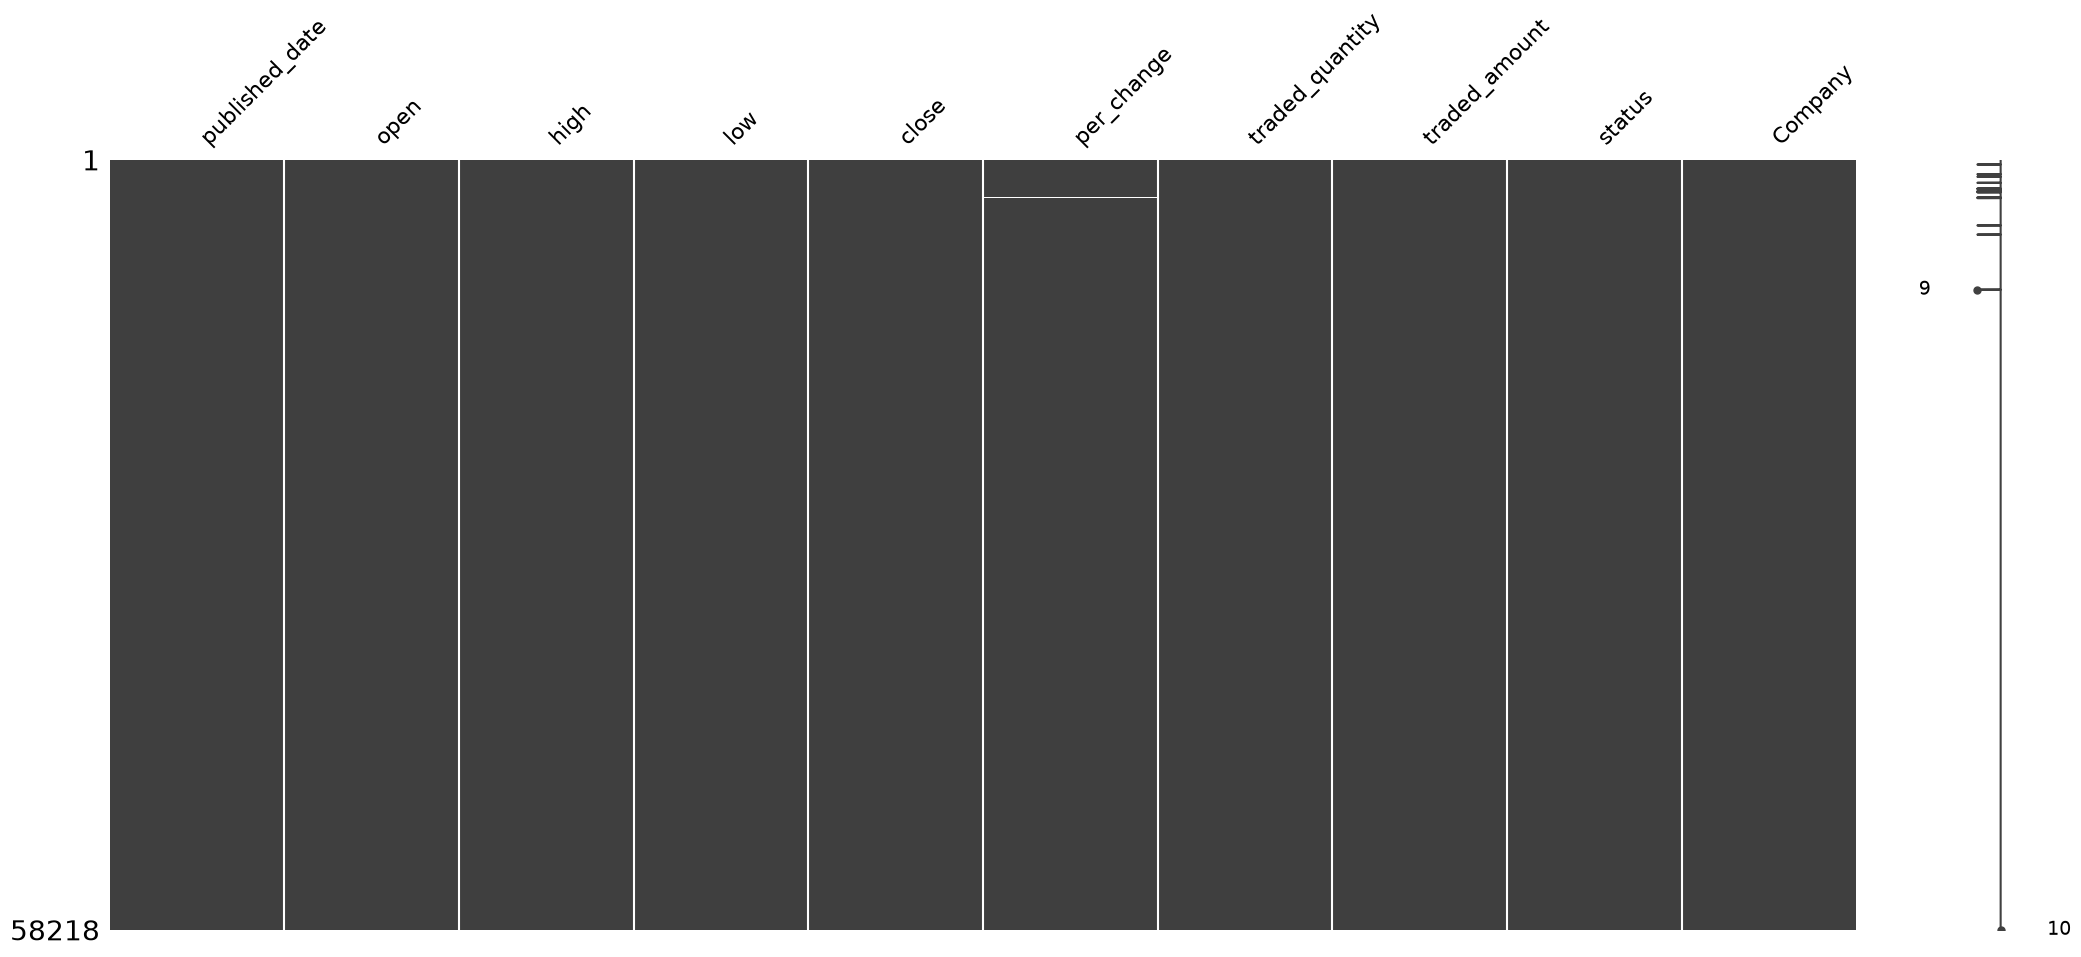

In [6]:
ms.matrix(nepse_data)

In [7]:
nepse_data.shape

(58218, 10)

# F = Data Filter

## company data fiter

In [8]:
nepse_data['Company'].value_counts()

Company
CHCL     4479
CZBIL    3929
AHPC     3779
ADBL     3679
NTC      3539
NABIL    3529
EBL      3529
SCB      3529
NLIC     3379
KBL      3337
LICN     3279
CIT      3079
SHPC     2879
GBIME    2785
BBC      2386
HDL      2249
STC      1627
NFS      1579
NIMB      838
TAMOR     809
Name: count, dtype: int64

### pie-chart

In [9]:
# # pie-chatt
# plt.figure(figsize = (10, 10))
# explode = [0.2,0.2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.2]
# plt.pie(nepse_data['Company'].value_counts(), autopct='%1.2f%%', labels=tickers, explode= explode)
# plt.show()

### bar graphy traded amount

In [10]:
nepse_data.groupby('Company')['traded_amount'].sum()

Company
ADBL     4.198486e+10
AHPC     1.092338e+11
BBC      5.384256e+09
CHCL     6.757345e+10
CIT      6.428358e+10
CZBIL    4.565516e+10
EBL      7.923509e+10
GBIME    8.283032e+10
HDL      1.293306e+11
KBL      9.335805e+10
LICN     4.147640e+10
NABIL    1.130294e+11
NFS      4.836118e+10
NIMB     2.442536e+10
NLIC     1.303170e+11
NTC      7.979033e+10
SCB      4.151074e+10
SHPC     9.523768e+10
STC      2.211366e+10
TAMOR    2.006379e+10
Name: traded_amount, dtype: float64

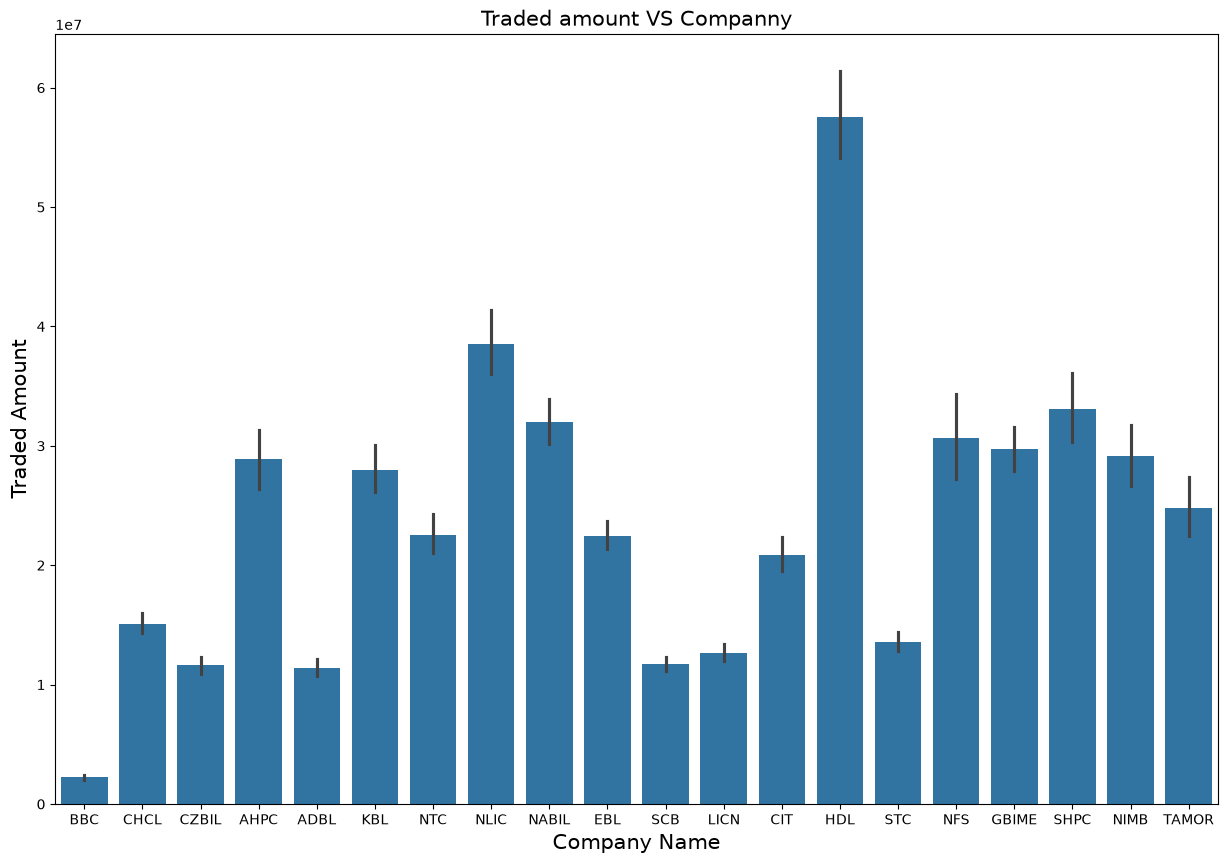

In [11]:
plt.figure(figsize = (15,10))
sns.barplot(data = nepse_data, x = 'Company', y = 'traded_amount' )
plt.xlabel( 'Company Name', fontsize = 15)
plt.ylabel('Traded Amount', fontsize = 15)
plt.title('Traded amount VS Companny', fontsize = 15)
plt.show()

### bar graph for traded quantity

In [12]:
nepse_data.groupby('Company')['traded_quantity'].sum()

Company
ADBL     104994539.0
AHPC     311907437.0
BBC        1306046.0
CHCL     104783612.0
CIT       23197745.0
CZBIL    155188672.0
EBL       92678757.0
GBIME    267867589.0
HDL       62418623.0
KBL      388106166.0
LICN      26253519.0
NABIL    125662746.0
NFS       63006312.0
NIMB     116193556.0
NLIC      99452685.0
NTC       77811554.0
SCB       49810214.0
SHPC     192408738.0
STC        4117334.0
TAMOR     43338462.0
Name: traded_quantity, dtype: float64

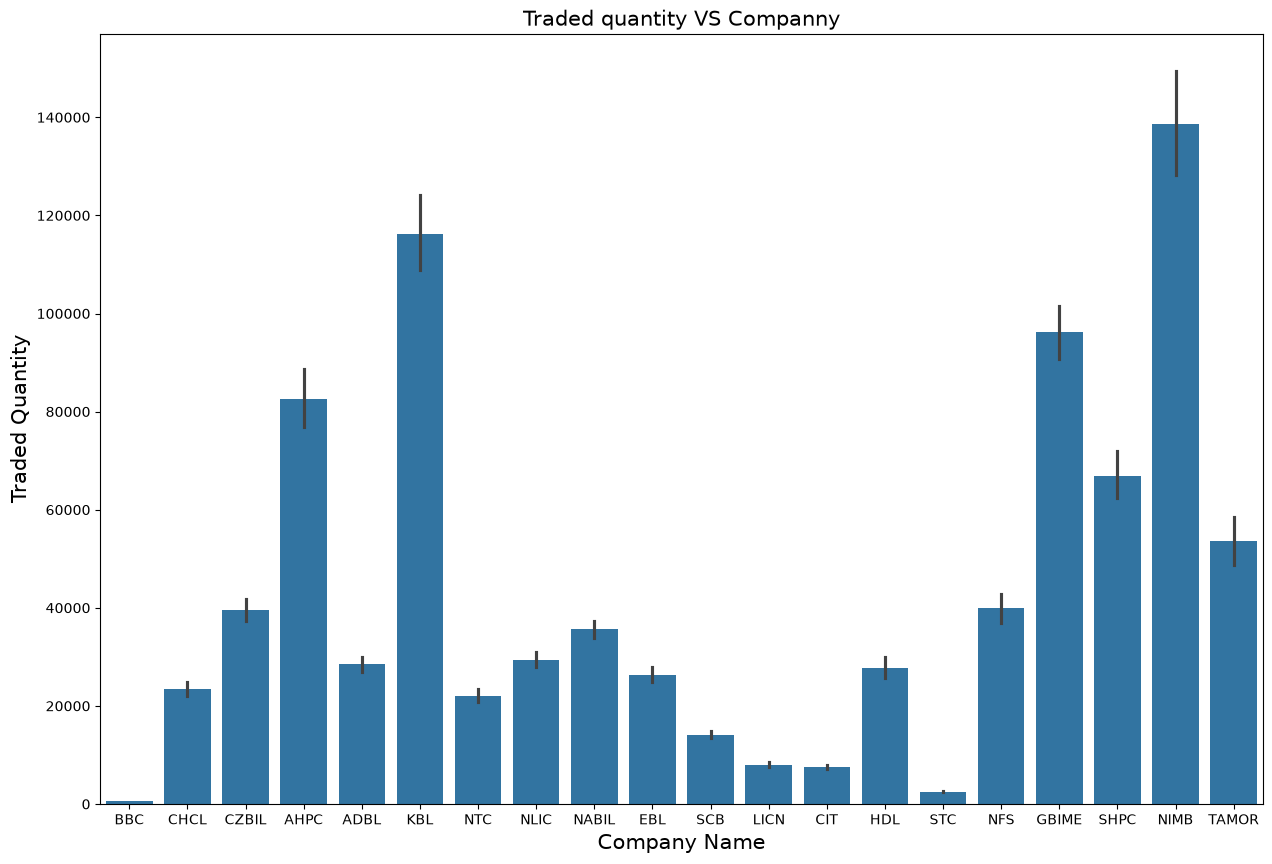

In [13]:
plt.figure(figsize = (15,10))
sns.barplot(data = nepse_data, x = 'Company', y = 'traded_quantity' )
plt.xlabel( 'Company Name', fontsize = 15)
plt.ylabel('Traded Quantity', fontsize = 15)
plt.title('Traded quantity VS Companny', fontsize = 15)
plt.show()

## seperatiing published_date into year month and day


In [14]:
nepse_copy = nepse_data.copy()

nepse_copy['year'] = pd.to_datetime(nepse_copy['published_date']).dt.year
nepse_copy['month'] = pd.to_datetime(nepse_copy['published_date']).dt.month
nepse_copy['day'] = pd.to_datetime(nepse_copy['published_date']).dt.day

nepse_copy.head()

,published_date,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company,year,month,day
0,1995-07-20,2220.0,2220.0,2220.0,2220.0,0.0,560.0,0.0,0,BBC,1995,7,20
1,1995-07-26,2220.0,2442.0,2442.0,2442.0,0.0,150.0,0.0,0,BBC,1995,7,26
2,1995-07-30,2442.0,2500.0,2500.0,2500.0,0.0,200.0,0.0,0,BBC,1995,7,30
3,1995-08-02,2500.0,2501.0,2501.0,2501.0,0.0,18.0,0.0,0,BBC,1995,8,2
4,1995-08-06,2501.0,2500.0,2500.0,2500.0,0.0,40.0,0.0,0,BBC,1995,8,6


### droping column published_date from nepse_copy

In [15]:
nepse_copy.drop(columns = 'published_date', inplace= True)

## Time-Series analysis

### line-graph traded amount by year

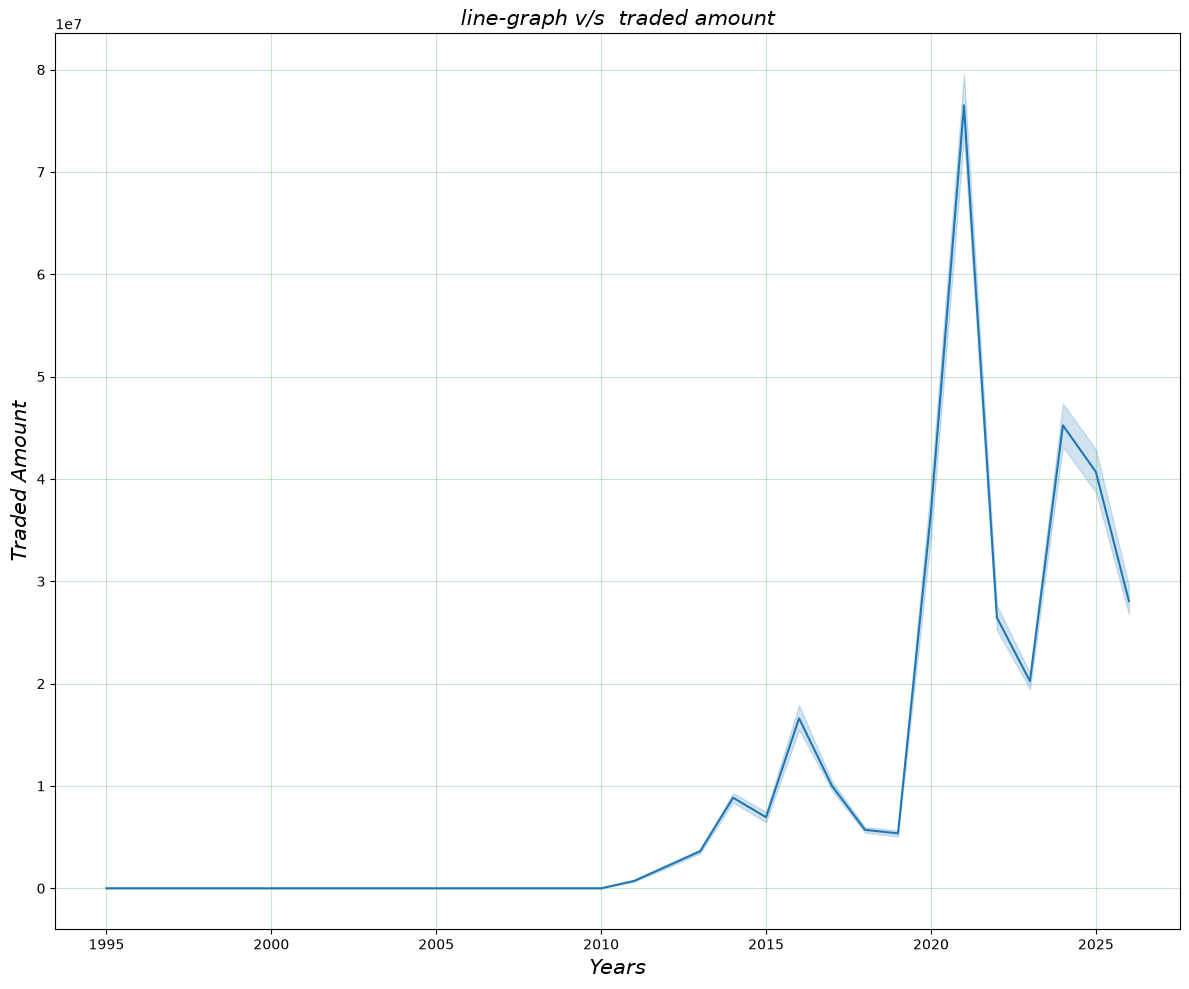

In [16]:
plt.figure(figsize=(12, 10))
sns.lineplot(data = nepse_copy, x = 'year', y = 'traded_amount')
plt.xlabel('Years', fontsize = 15, fontstyle = 'oblique')
plt.ylabel('Traded Amount', fontsize = 15, fontstyle = 'oblique')
plt.title('line-graph v/s  traded amount', fontsize = 15, fontstyle = 'oblique')
plt.grid(c = 'g', alpha = 0.2)
plt.tight_layout()
plt.show()

### Line graph for traded quantity

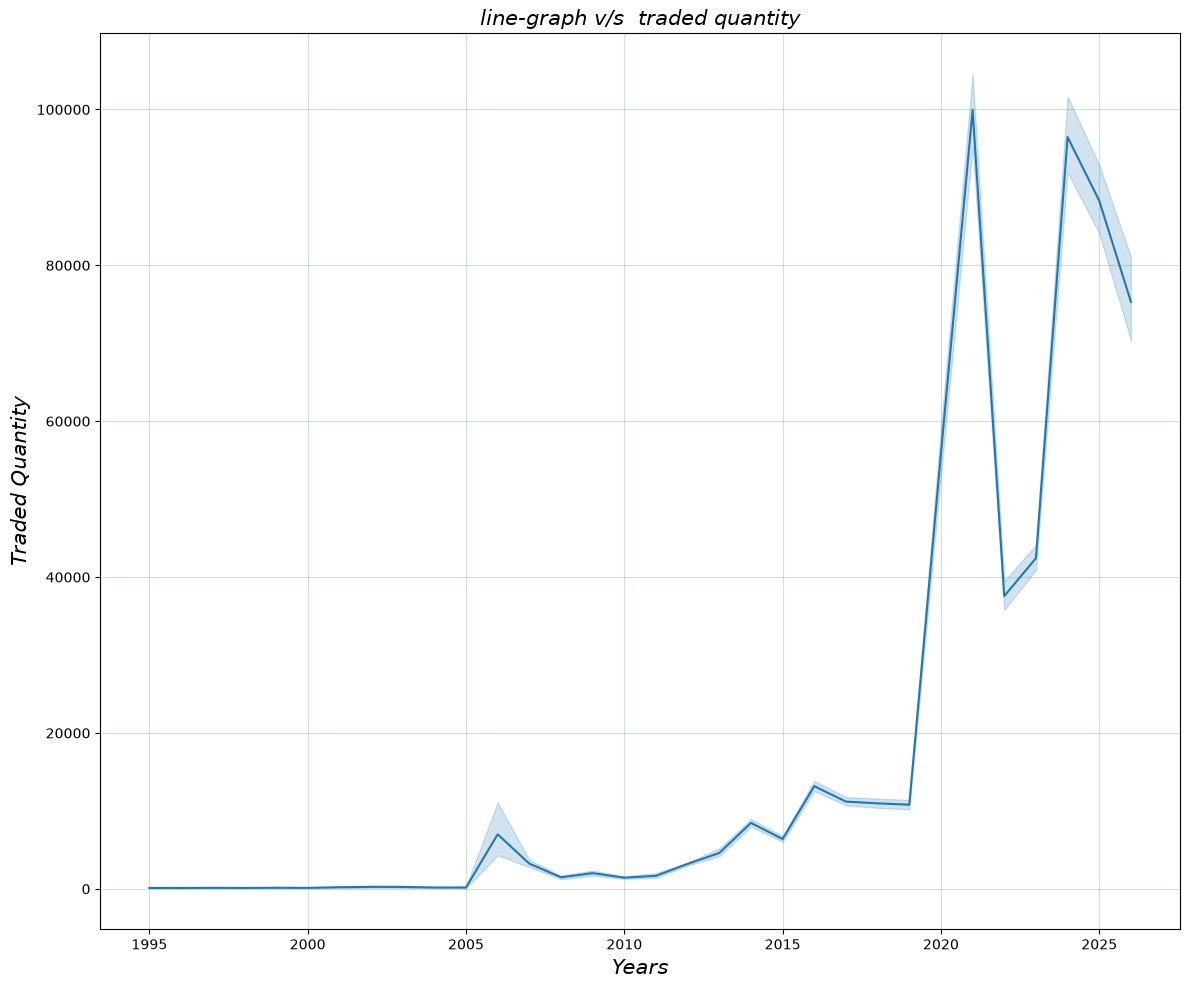

In [17]:
plt.figure(figsize=(12, 10))
sns.lineplot(data = nepse_copy, x = 'year', y = 'traded_quantity')
plt.xlabel('Years', fontsize = 15, fontstyle = 'oblique')
plt.ylabel('Traded Quantity', fontsize = 15, fontstyle = 'oblique')
plt.title('line-graph v/s  traded quantity', fontsize = 15, fontstyle = 'oblique')
plt.grid(c = 'g', alpha = 0.2)
plt.tight_layout()
plt.show()

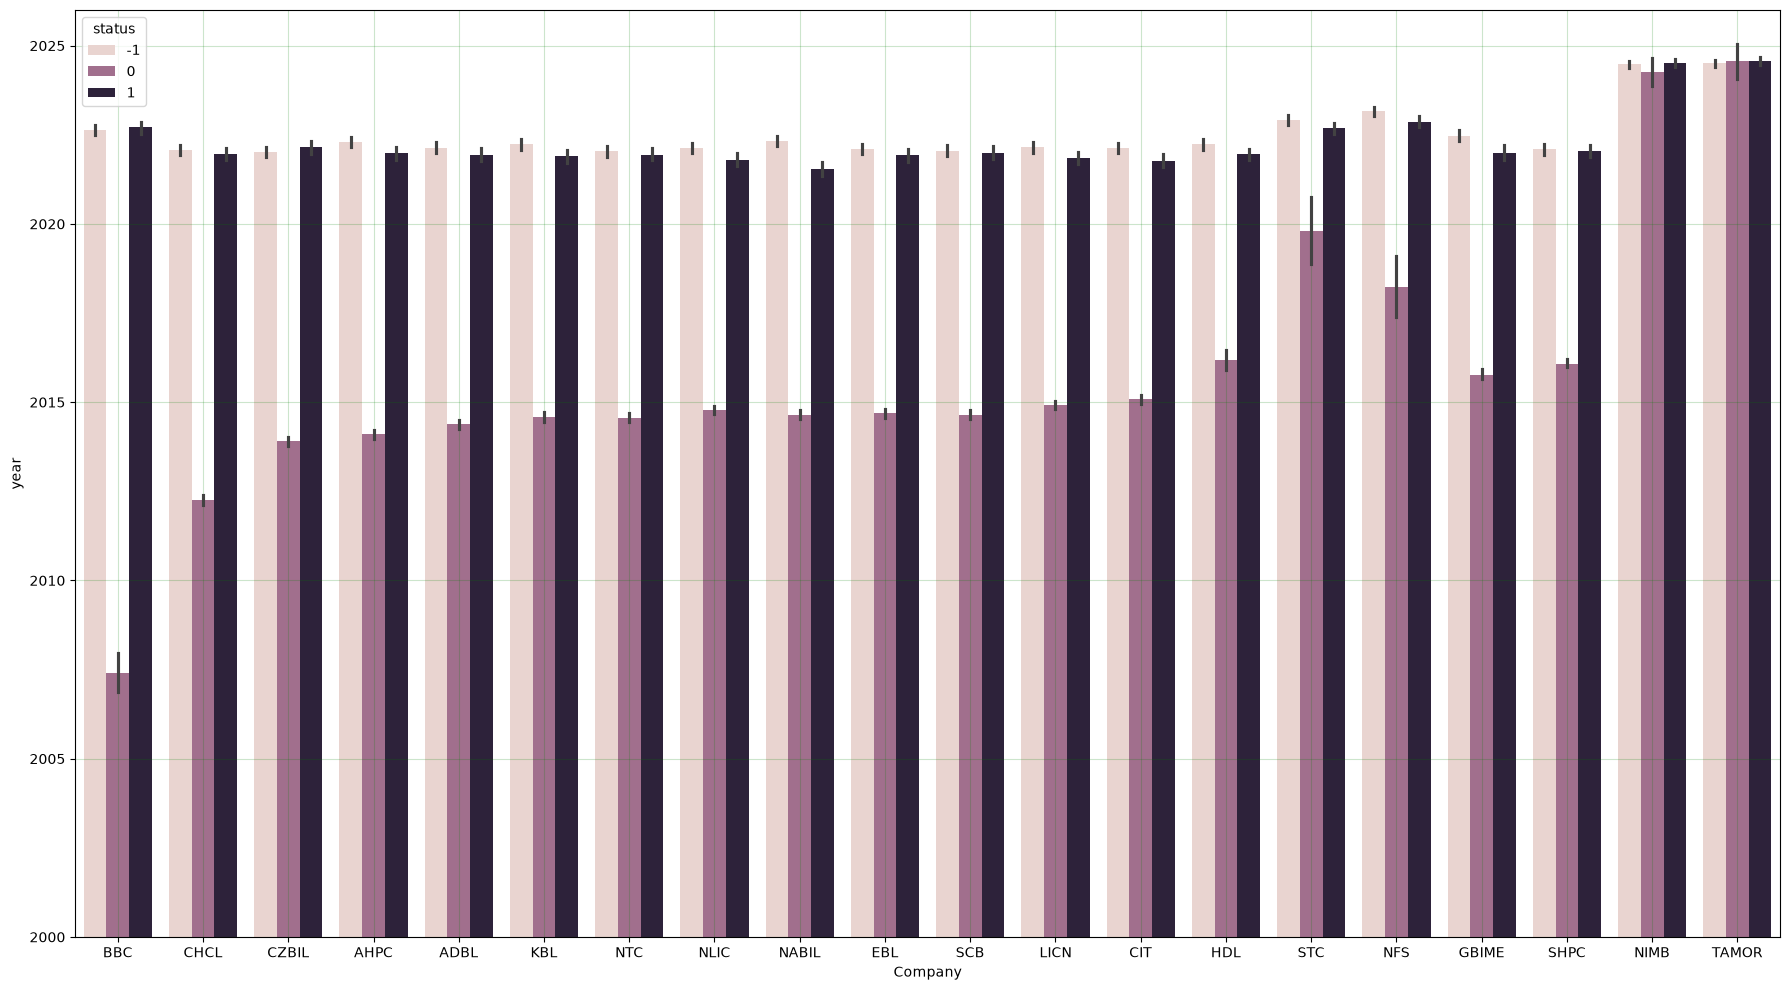

In [18]:
# status
plt.figure(figsize= (18, 10))
sns.barplot(data = nepse_copy, x = 'Company', y = 'year', hue = 'status')
plt.ylim((2000, 2026))
plt.grid(c = 'g', alpha = 0.2)
plt.margins(y = 0.1)
plt.tight_layout()
plt.show()


### Time series by Month

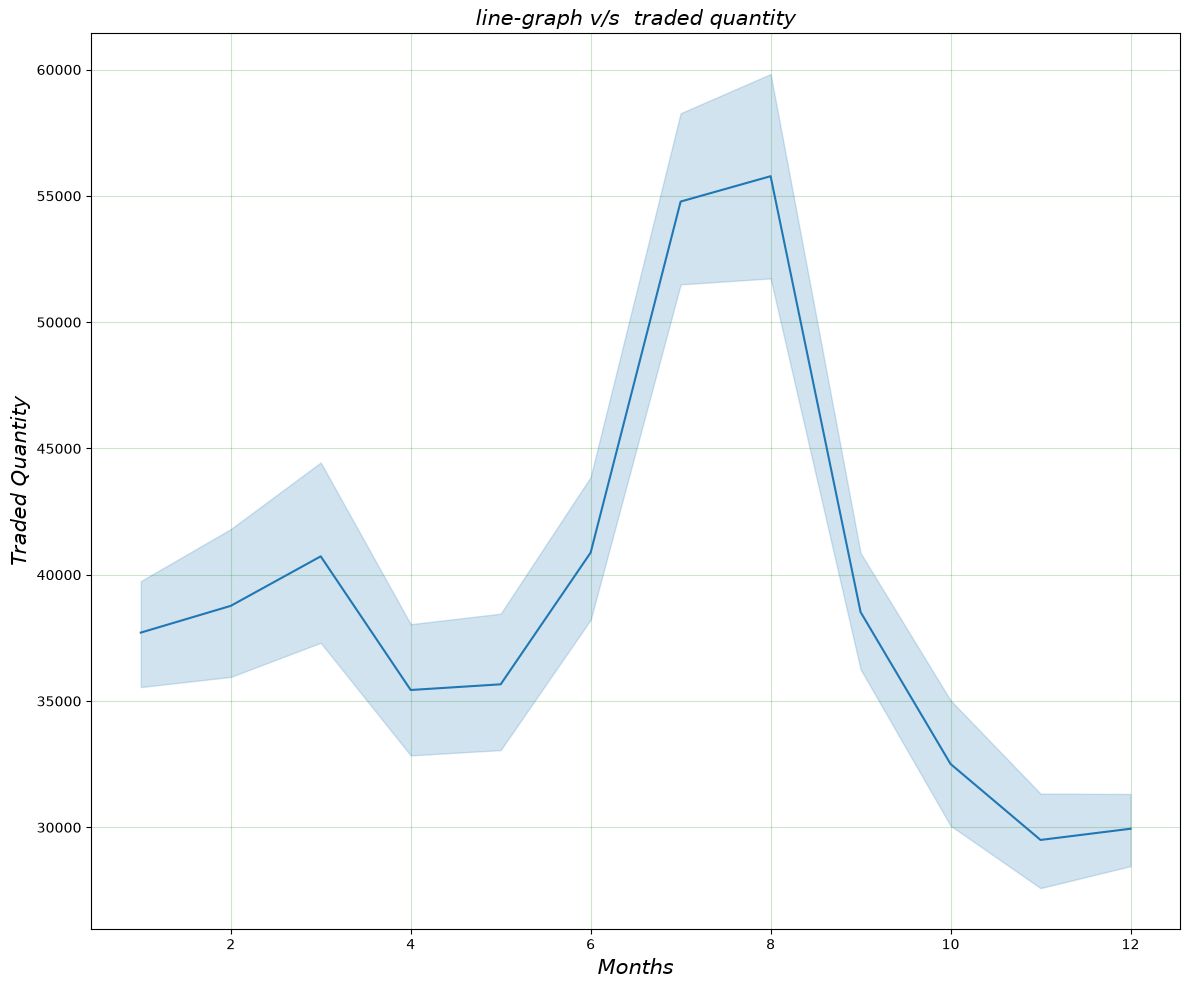

In [19]:
plt.figure(figsize=(12, 10))
sns.lineplot(data = nepse_copy, x = 'month', y = 'traded_quantity')
plt.xlabel('Months', fontsize = 15, fontstyle = 'oblique')
plt.ylabel('Traded Quantity', fontsize = 15, fontstyle = 'oblique')
plt.title('line-graph v/s  traded quantity', fontsize = 15, fontstyle = 'oblique')
plt.grid(c = 'g', alpha = 0.2)
plt.tight_layout()
plt.show()

## 2025 opening price

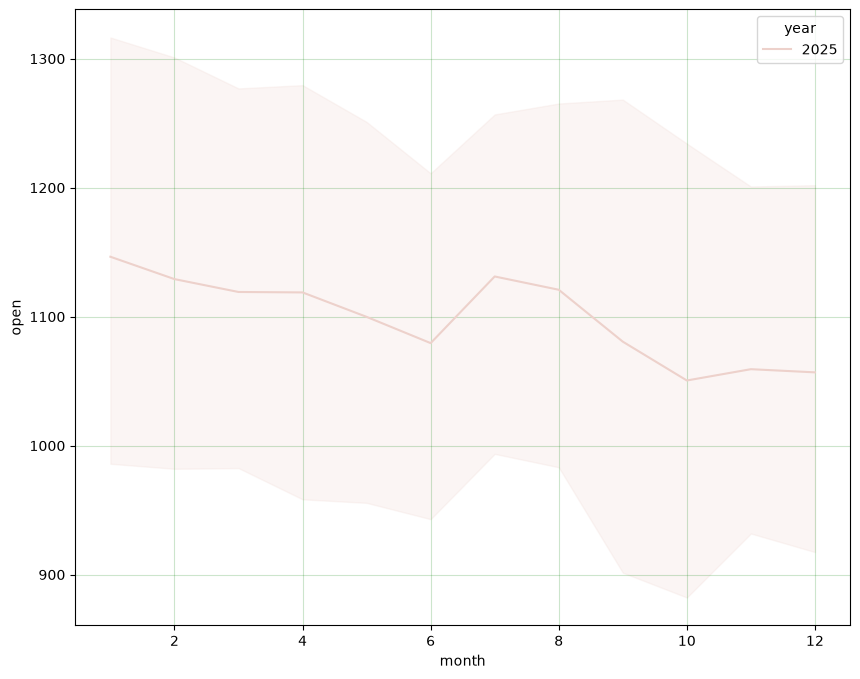

In [20]:
# 1. Filter the DataFrame first for the year 2025
plt.figure(figsize = (10, 8))
filtered_data = nepse_copy[nepse_copy['year'] == 2025]
sns.lineplot(data = filtered_data, x = 'month', y = 'open', hue = 'year')
plt.grid(c ='g', alpha = 0.2)
plt.show()

### 2026 opening vs 2025 opening amount

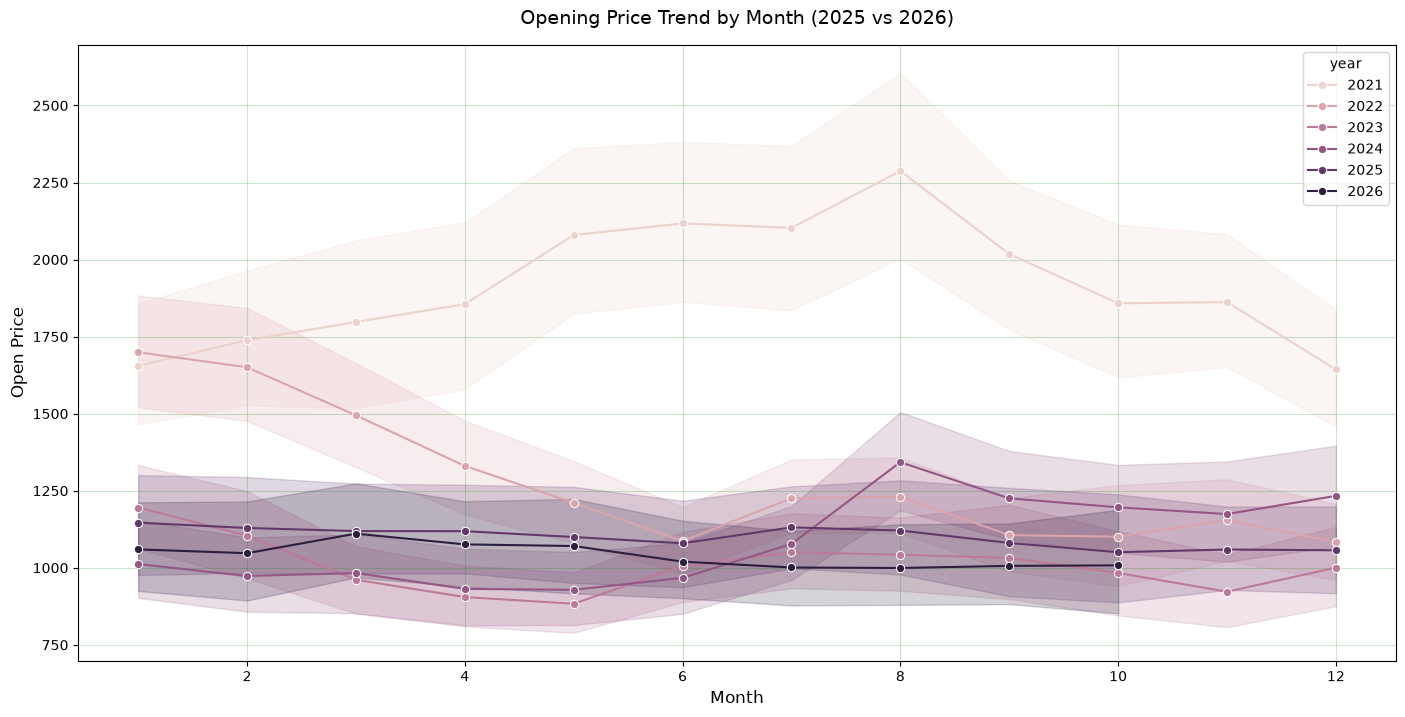

In [21]:

# 1. Properly filter for both years 2025 and 2026 using .isin()
filtered_data = nepse_copy[nepse_copy['year'].isin([2024,2023,2022,2021,2025, 2026])]

# 2. Create the line plot
plt.figure(figsize=(17, 8))
sns.lineplot(
    data=filtered_data,
    x='month',
    y='open',
    hue='year',
    marker='o',  # Optional: adds dots to the lines for clearer data points
)

plt.grid(c='g', alpha=0.2)
plt.title('Opening Price Trend by Month (2025 vs 2026)', fontsize=14, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Open Price', fontsize=12)

plt.show()

### closing analysis

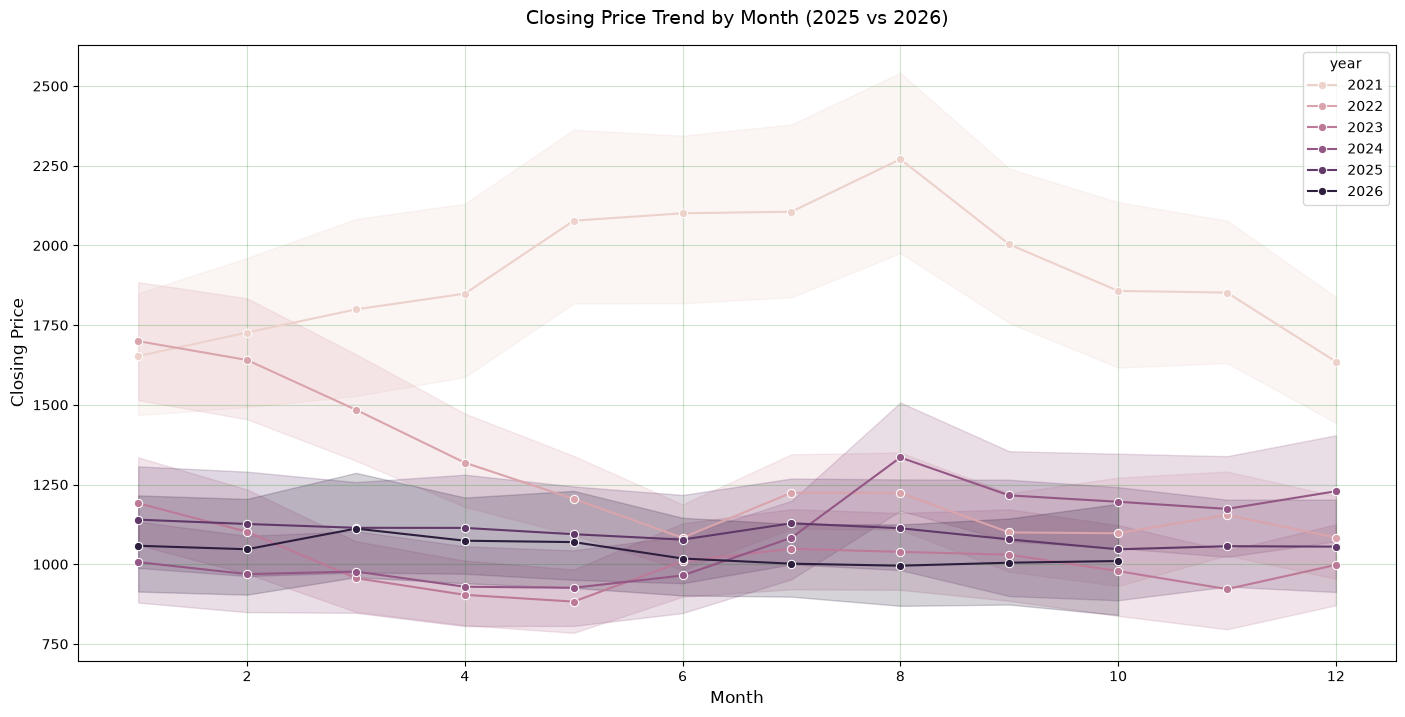

In [22]:
# 1. Properly filter for both years 2025 and 2026 using .isin()
filtered_data = nepse_copy[nepse_copy['year'].isin([2024,2023,2022,2021,2025, 2026])]

# 2. Create the line plot
plt.figure(figsize=(17, 8))
sns.lineplot(
    data=filtered_data,
    x='month',
    y='close',
    hue='year',
    marker='o',  # Optional: adds dots to the lines for clearer data points
)

plt.grid(c='g', alpha=0.2)
plt.title('Closing Price Trend by Month (2025 vs 2026)', fontsize=14, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Closing Price', fontsize=12)

plt.show()

# T = Transforming Data

## correlation


In [23]:
# correlation
nepse_data.corr(numeric_only=True)

,open,high,low,close,per_change,traded_quantity,traded_amount,status
open,1.000000,0.999523,0.999662,0.999392,-0.002100,-0.177374,0.041298,0.013971
high,0.999523,1.000000,0.999501,0.999724,0.010969,-0.175542,0.044958,0.019150
low,0.999662,0.999501,1.000000,0.999694,0.008081,-0.178772,0.038841,0.018099
close,0.999392,0.999724,0.999694,1.000000,0.016298,-0.177202,0.042208,0.023379
per_change,-0.002100,0.010969,0.008081,0.016298,1.000000,0.072051,0.080409,0.369000
traded_quantity,-0.177374,-0.175542,-0.178772,-0.177202,0.072051,1.000000,0.736177,0.027256
traded_amount,0.041298,0.044958,0.038841,0.042208,0.080409,0.736177,1.000000,0.038151
status,0.013971,0.019150,0.018099,0.023379,0.369000,0.027256,0.038151,1.000000


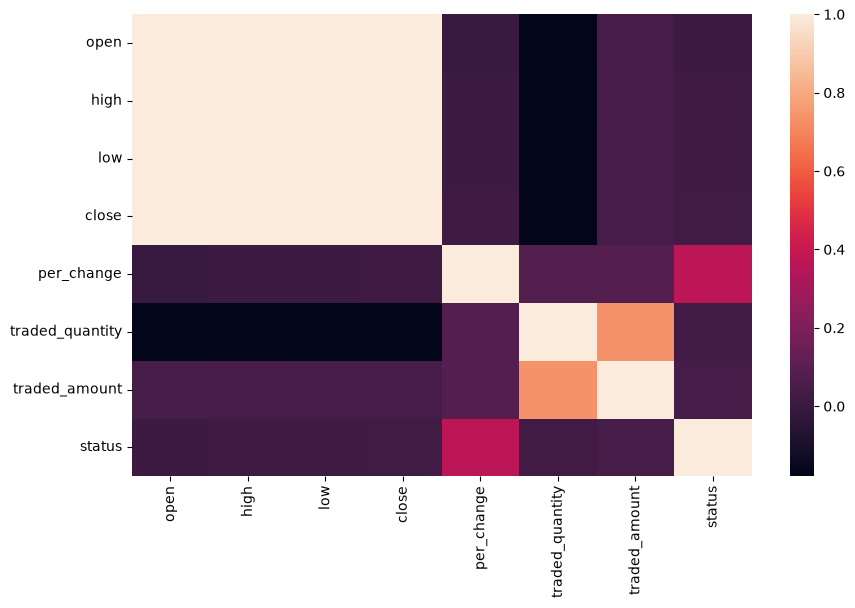

In [24]:
plt.figure(figsize=(10, 6))
sns.heatmap(nepse_data.corr(numeric_only=True))
plt.show()

## MACD INDICATOR column

In [25]:
# 1. Calculate the 12-period and 26-period EMAs of the Closing price
ema_12 = nepse_copy['close'].ewm(span=12, adjust=False).mean()
ema_26 = nepse_copy['close'].ewm(span=26, adjust=False).mean()

# 2. Compute the MACD Line
nepse_copy['macd'] = ema_12 - ema_26

# 3. Compute the Signal Line (9-period EMA of the MACD Line)
nepse_copy['macd_signal'] = nepse_copy['macd'].ewm(span=9, adjust=False).mean()

# 4. Compute the Histogram
nepse_copy['macd_histogram'] = nepse_copy['macd'] - nepse_copy['macd_signal']

### amount strength multiplier

In [26]:
# 1. Calculate the 20-day moving average of traded amount
nepse_copy['amount_sma20'] = nepse_copy['traded_amount'].rolling(window=20).mean()

# 2. Calculate Turnover Strength Multiplier
nepse_copy['strength_multiplier'] = nepse_copy['traded_amount'] / nepse_copy['amount_sma20']

In [27]:
nepse_copy

,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company,year,month,day,macd,macd_signal,macd_histogram,amount_sma20,strength_multiplier
0,2220.0,2220.0,2220.0,2220.0,0.00,560.0,0.0,0,BBC,1995,7,20,0.000000,0.000000,0.000000,NaN,NaN
1,2220.0,2442.0,2442.0,2442.0,0.00,150.0,0.0,0,BBC,1995,7,26,17.709402,3.541880,14.167521,NaN,NaN
2,2442.0,2500.0,2500.0,2500.0,0.00,200.0,0.0,0,BBC,1995,7,30,36.009253,10.035355,25.973898,NaN,NaN
3,2500.0,2501.0,2501.0,2501.0,0.00,18.0,0.0,0,BBC,1995,8,2,50.016154,18.031515,31.984639,NaN,NaN
4,2501.0,2500.0,2500.0,2500.0,0.00,40.0,0.0,0,BBC,1995,8,6,60.340465,26.493305,33.847160,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58213,920.0,925.0,915.0,920.0,1.10,19118.0,17559337.2,0,NTC,2026,10,16,-122.058040,-94.587659,-27.470380,4.428457e+07,0.396511
58214,672.0,679.8,672.0,679.0,0.15,11819.0,8001423.0,1,SCB,2026,10,16,-117.578164,-99.185760,-18.392404,4.393834e+07,0.182106
58215,527.9,536.0,527.0,535.0,1.13,40550.0,21621875.2,1,SHPC,2026,10,16,-124.215547,-104.191718,-20.023830,4.382569e+07,0.493361
58216,5597.0,5597.0,5543.1,5591.0,0.56,347.0,1930122.3,-1,STC,2026,10,16,275.327421,-28.287890,303.615311,4.381917e+07,0.044047


In [28]:
nepse_copy.isna().sum()

open                      0
high                      0
low                       0
close                     0
per_change               14
traded_quantity           0
traded_amount             0
status                    0
Company                   0
year                      0
month                     0
day                       0
macd                      0
macd_signal               0
macd_histogram            0
amount_sma20             19
strength_multiplier    2175
dtype: int64

In [29]:


# 1. Create chronological ordering date and sort
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date'])

# 2. Vectorized calculation of EMAs per company using groupby transform
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# 3. Volume Strength Filter (min_periods=1 prevents NaNs)
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# 4. Signal Generation & Daily Returns
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

nepse_copy['daily_return'] = nepse_copy.groupby('Company')['close'].pct_change().fillna(0.0)

# Strategy return: yesterday's signal * today's return
nepse_copy['strategy_return'] = nepse_copy.groupby('Company')['signal'].shift(1).fillna(0) * nepse_copy['daily_return']

# 5. Cumulative growth factor per company
nepse_copy['cumulative_growth'] = nepse_copy.groupby('Company')['strategy_return'].transform(lambda x: (1.0 + x).cumprod())
nepse_copy['cumulative_growth'] = nepse_copy['cumulative_growth'].replace([np.inf, -np.inf], np.nan).fillna(1.0)

# 6. Select top 20 companies
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()

# Drop duplicate rows for the same company on the same date (keeps the last entry)
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Pivot table safely
growth_pivot = portfolio_subset.pivot(index='temp_date', columns='Company', values='cumulative_growth')
growth_pivot = growth_pivot.ffill().fillna(1.0)

# 7. Portfolio Simulation: NPR 200,000 total -> NPR 10,000 per company
initial_capital_per_stock = 10000 
portfolio_values = growth_pivot * initial_capital_per_stock
total_portfolio_value = portfolio_values.sum(axis=1)

# Results
start_value = total_portfolio_value.iloc[0]
final_value = total_portfolio_value.iloc[-1]

print(f"Initial Portfolio Investment (2015): NPR {start_value:,.2f}")
print(f"Predicted Portfolio Value (2026): NPR {final_value:,.2f}")
print(f"Total Return Multiplier: {final_value / start_value:.2f}x")

Initial Portfolio Investment (2015): NPR 200,000.00
Predicted Portfolio Value (2026): NPR 624,141.94
Total Return Multiplier: 3.12x


In [30]:
import pandas as pd
import numpy as np

# 1. Create chronological ordering date and sort
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy[['year', 'month', 'day']])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date'])

# 2. Vectorized calculation of EMAs per company using groupby transform
ema_12 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
ema_26 = nepse_copy.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())

nepse_copy['macd'] = (ema_12 - ema_26).fillna(0)
nepse_copy['macd_signal'] = nepse_copy.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean()).fillna(0)

# 3. Volume Strength Filter (min_periods=1 prevents NaNs)
nepse_copy['vol_sma20'] = nepse_copy.groupby('Company')['traded_quantity'].transform(lambda x: x.rolling(window=20, min_periods=1).mean())
nepse_copy['vol_strength'] = np.where(
    nepse_copy['vol_sma20'] > 0, 
    nepse_copy['traded_quantity'] / nepse_copy['vol_sma20'], 
    1.0
)

# 4. Signal Generation & Daily Returns
nepse_copy['signal'] = np.where(
    (nepse_copy['macd'] > nepse_copy['macd_signal']) & (nepse_copy['vol_strength'] >= 1.0), 
    1, 
    0
)

nepse_copy['daily_return'] = nepse_copy.groupby('Company')['close'].pct_change().fillna(0.0)

# Strategy return: yesterday's signal * today's return
nepse_copy['strategy_return'] = nepse_copy.groupby('Company')['signal'].shift(1).fillna(0) * nepse_copy['daily_return']

# 5. Cumulative growth factor per company
nepse_copy['cumulative_growth'] = nepse_copy.groupby('Company')['strategy_return'].transform(lambda x: (1.0 + x).cumprod())
nepse_copy['cumulative_growth'] = nepse_copy['cumulative_growth'].replace([np.inf, -np.inf], np.nan).fillna(1.0)

# 6. Select top 20 companies and clean duplicates
top_20_companies = nepse_copy['Company'].unique()[:20]
portfolio_subset = nepse_copy[nepse_copy['Company'].isin(top_20_companies)].copy()
portfolio_subset = portfolio_subset.drop_duplicates(subset=['Company', 'temp_date'], keep='last')

# Pivot table safely
growth_pivot = portfolio_subset.pivot(index='temp_date', columns='Company', values='cumulative_growth')
growth_pivot = growth_pivot.ffill().fillna(1.0)

# 7. Portfolio Simulation: NPR 200,000 total -> NPR 10,000 per company
initial_capital_per_stock = 10000 
company_portfolio_values = growth_pivot * initial_capital_per_stock

# --- INDIVIDUAL COMPANY PERFORMANCE REPORT ---
summary_list = []
for company in growth_pivot.columns:
    comp_series = company_portfolio_values[company].dropna()
    if len(comp_series) > 0:
        start_val = comp_series.iloc[0]
        final_val = comp_series.iloc[-1]
        multiplier = final_val / start_val if start_val > 0 else 1.0
        summary_list.append({
            'Company': company,
            'Initial (NPR)': start_val,
            'Predicted 2026 (NPR)': final_val,
            'Multiplier': multiplier
        })

summary_df = pd.DataFrame(summary_list)
print("--- Per-Company Backtest Performance Report (2015 - 2026) ---")
print(summary_df.to_string(index=False))
print("\n" + "="*60 + "\n")

# --- COMBINED PORTFOLIO SUMMARY ---
total_portfolio_value = company_portfolio_values.sum(axis=1)
total_start = total_portfolio_value.iloc[0]
total_final = total_portfolio_value.iloc[-1]

print(f"Total Initial Portfolio Investment (2015): NPR {total_start:,.2f}")
print(f"Total Predicted Portfolio Value (2026): NPR {total_final:,.2f}")
print(f"Overall Portfolio Return Multiplier: {total_final / total_start:.2f}x")

--- Per-Company Backtest Performance Report (2015 - 2026) ---
Company  Initial (NPR)  Predicted 2026 (NPR)  Multiplier
   ADBL        10000.0          19080.520921    1.908052
   AHPC        10000.0          72652.387851    7.265239
    BBC        10000.0          40175.512164    4.017551
   CHCL        10000.0           4398.105658    0.439811
    CIT        10000.0          79314.493203    7.931449
  CZBIL        10000.0          14786.024979    1.478602
    EBL        10000.0           7347.167808    0.734717
  GBIME        10000.0          20201.968742    2.020197
    HDL        10000.0          34191.342898    3.419134
    KBL        10000.0          31409.277193    3.140928
   LICN        10000.0          52235.310740    5.223531
  NABIL        10000.0          13431.408777    1.343141
    NFS        10000.0          31551.436152    3.155144
   NIMB        10000.0          11330.720173    1.133072
   NLIC        10000.0          22892.046097    2.289205
    NTC        10000.0    

# buy | sell through macd indicator

## loop buy sell

### Final 

In [31]:
import os
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# Ensure separate output folder exists
output_dir = "NEPSE_Trading_Reports"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------------------------
# 1. SETUP & DATA CLEANING (Using Actual Tickers / nepse_copy Dataset)
# ------------------------------------------------------------------------------
# Ensure nepse_copy is sorted chronologically by Company and temp_date
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy['temp_date'])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# NEPSE Trading Fee Functions (Zero Tax / Pure Fees)
def calculate_buy_cost(quantity, price):
    gross = quantity * price
    broker_comm = gross * 0.0036
    sebon_fee = gross * 0.00015
    dp_fee = 25.0
    total_cost = gross + broker_comm + sebon_fee + dp_fee
    fees = broker_comm + sebon_fee + dp_fee
    return round(total_cost, 2), round(fees, 2)

def calculate_sell_proceeds(quantity, price):
    gross = quantity * price
    broker_comm = gross * 0.0036
    sebon_fee = gross * 0.00015
    dp_fee = 25.0
    net_proceeds = gross - (broker_comm + sebon_fee + dp_fee)
    fees = broker_comm + sebon_fee + dp_fee
    return round(net_proceeds, 2), round(fees, 2)

INITIAL_BUDGET = 200000.0
MIN_QUANTITY = 10
COMPANY_ALLOCATION_LIMIT = 10000.0

cash_balance = INITIAL_BUDGET
completed_transactions = []
active_positions = []

simulation_dates = pd.date_range(start="2015-01-01", end="2026-03-31", freq="B")

# ------------------------------------------------------------------------------
# 2. DAY-BY-DAY REACTIVE TRADING SIMULATION LOOP
# ------------------------------------------------------------------------------
for curr_date in simulation_dates:
    daily_data = nepse_copy[nepse_copy['temp_date'] == curr_date]
    date_str = curr_date.strftime('%Y-%m-%d')
    
    # Process Exits (Bearish MACD crossover or stop-loss <= -4%)
    remaining_open = []
    for pos in active_positions:
        comp_data = daily_data[daily_data['Company'] == pos['Company']]
        if len(comp_data) > 0:
            curr_row = comp_data.iloc[0]
            curr_price = float(curr_row['close'])
            curr_macd = float(curr_row['macd'])
            curr_signal = float(curr_row['macd_signal'])
            
            sell_proceeds, sell_fees = calculate_sell_proceeds(pos['buy_quantity'], curr_price)
            ret_pct = (sell_proceeds - pos['Total_amount_buyCost']) / pos['Total_amount_buyCost']
            
            is_bearish_crossover = curr_macd < curr_signal
            if is_bearish_crossover or ret_pct <= -0.04:
                cash_balance += sell_proceeds
                pnl = round(sell_proceeds - pos['Total_amount_buyCost'], 2)
                pnl_pct = round((pnl / pos['Total_amount_buyCost']) * 100, 2)
                
                completed_transactions.append({
                    'Company': pos['Company'],
                    'buy_date': pos['buy_date'],
                    'buy_quantity': pos['buy_quantity'],
                    'buy_rate': pos['buy_rate'],
                    'macd_on_buyDate': pos['macd_on_buyDate'],
                    'Total_amount_buyCost': pos['Total_amount_buyCost'],
                    'sell_date': date_str,
                    'sell_quantity': pos['buy_quantity'],
                    'sell_rate': curr_price,
                    'macd_on_sellingDate': round(curr_macd, 4),
                    'total_amount_recieved': sell_proceeds,
                    'profit/loss': pnl,
                    'profit/loss percentage respect to buy': pnl_pct
                })
            else:
                remaining_open.append(pos)
        else:
            remaining_open.append(pos)
    active_positions = remaining_open

    # Process Buys (Allows buying multiple qualifying stocks on same day if cash permits)
    if cash_balance > MIN_QUANTITY * 20:
import os
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# Ensure separate output folder exists
output_dir = "NEPSE_Trading_Reports"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------------------------
# 1. SETUP & DATA CLEANING (Using Actual Tickers / nepse_copy Dataset)
# ------------------------------------------------------------------------------
# Ensure nepse_copy is sorted chronologically by Company and temp_date
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy['temp_date'])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# NEPSE Trading Fee Functions (Zero Tax / Pure Fees)
def calculate_buy_cost(quantity, price):
    gross = quantity * price
    broker_comm = gross * 0.0036
    sebon_fee = gross * 0.00015
    dp_fee = 25.0
    total_cost = gross + broker_comm + sebon_fee + dp_fee
    fees = broker_comm + sebon_fee + dp_fee
    return round(total_cost, 2), round(fees, 2)

def calculate_sell_proceeds(quantity, price):
    gross = quantity * price
    broker_comm = gross * 0.0036
    sebon_fee = gross * 0.00015
    dp_fee = 25.0
    net_proceeds = gross - (broker_comm + sebon_fee + dp_fee)
    fees = broker_comm + sebon_fee + dp_fee
    return round(net_proceeds, 2), round(fees, 2)

INITIAL_BUDGET = 200000.0
MIN_QUANTITY = 10
COMPANY_ALLOCATION_LIMIT = 10000.0

cash_balance = INITIAL_BUDGET
completed_transactions = []
active_positions = []

simulation_dates = pd.date_range(start="2015-01-01", end="2026-03-31", freq="B")

# ------------------------------------------------------------------------------
# 2. DAY-BY-DAY REACTIVE TRADING SIMULATION LOOP
# ------------------------------------------------------------------------------
for curr_date in simulation_dates:
    daily_data = nepse_copy[nepse_copy['temp_date'] == curr_date]
    date_str = curr_date.strftime('%Y-%m-%d')
    
    # Process Exits (Bearish MACD crossover or stop-loss <= -4%)
    remaining_open = []
    for pos in active_positions:
        comp_data = daily_data[daily_data['Company'] == pos['Company']]
        if len(comp_data) > 0:
            curr_row = comp_data.iloc[0]
            curr_price = float(curr_row['close'])
            curr_macd = float(curr_row['macd'])
            curr_signal = float(curr_row['macd_signal'])
            
            sell_proceeds, sell_fees = calculate_sell_proceeds(pos['buy_quantity'], curr_price)
            ret_pct = (sell_proceeds - pos['Total_amount_buyCost']) / pos['Total_amount_buyCost']
            
            is_bearish_crossover = curr_macd < curr_signal
            if is_bearish_crossover or ret_pct <= -0.04:
                cash_balance += sell_proceeds
                pnl = round(sell_proceeds - pos['Total_amount_buyCost'], 2)
                pnl_pct = round((pnl / pos['Total_amount_buyCost']) * 100, 2)
                
                completed_transactions.append({
                    'Company': pos['Company'],
                    'buy_date': pos['buy_date'],
                    'buy_quantity': pos['buy_quantity'],
                    'buy_rate': pos['buy_rate'],
                    'macd_on_buyDate': pos['macd_on_buyDate'],
                    'Total_amount_buyCost': pos['Total_amount_buyCost'],
                    'sell_date': date_str,
                    'sell_quantity': pos['buy_quantity'],
                    'sell_rate': curr_price,
                    'macd_on_sellingDate': round(curr_macd, 4),
                    'total_amount_recieved': sell_proceeds,
                    'profit/loss': pnl,
                    'profit/loss percentage respect to buy': pnl_pct
                })
            else:
                remaining_open.append(pos)
        else:
            remaining_open.append(pos)
    active_positions = remaining_open

    # Process Buys (Allows buying multiple qualifying stocks on same day if cash permits)
    if cash_balance > MIN_QUANTITY * 20:
        buy_candidates = daily_data[daily_data['signal'] == 1]
        held_companies = {pos['Company'] for pos in active_positions}
        buy_candidates = buy_candidates[~buy_candidates['Company'].isin(held_companies)]
        
        if len(buy_candidates) > 0:
            buy_candidates = buy_candidates.sort_values(by='macd_histogram', ascending=False)
            
            for _, cand in buy_candidates.iterrows():
                b_price = float(cand['close'])
                b_macd = round(float(cand['macd']), 4)
                comp_name = cand['Company']
                
                min_buy_cost, min_fees = calculate_buy_cost(MIN_QUANTITY, b_price)
                if cash_balance >= min_buy_cost:
                    max_spend = min(COMPANY_ALLOCATION_LIMIT, cash_balance)
                    raw_qty = int((max_spend - 25) // (b_price * 1.004))
                    buy_qty = max(MIN_QUANTITY, raw_qty)
                    
                    buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_price)
                    while buy_cost > cash_balance and buy_qty > MIN_QUANTITY:
                        buy_qty -= 1
                        buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_price)
                        
                    if buy_cost <= cash_balance:
                        cash_balance -= buy_cost
                        active_positions.append({
                            'Company': comp_name,
                            'buy_date': date_str,
                            'buy_quantity': buy_qty,
                            'buy_rate': b_price,
                            'macd_on_buyDate': b_macd,
                            'Total_amount_buyCost': buy_cost
                        })

# ------------------------------------------------------------------------------
# 3. TRACK OPEN / UNSOLD POSITIONS AT FINAL DATE (NO COMPULSORY SELL)
# ------------------------------------------------------------------------------
unsold_shares_value = 0.0
unsold_records = []
final_day_data = nepse_copy[nepse_copy['temp_date'] == simulation_dates[-1]]

for pos in active_positions:
    comp_final = final_day_data[final_day_data['Company'] == pos['Company']]
    if len(comp_final) > 0:
        fp = float(comp_final.iloc[0]['close'])
        f_macd = round(float(comp_final.iloc[0]['macd']), 4)
        val, _ = calculate_sell_proceeds(pos['buy_quantity'], fp)
        unsold_shares_value += val
        
        pnl = round(val - pos['Total_amount_buyCost'], 2)
        pnl_pct = round((pnl / pos['Total_amount_buyCost']) * 100, 2)
        
        unsold_records.append({
            'Company': pos['Company'],
            'buy_date': pos['buy_date'],
            'buy_quantity': pos['buy_quantity'],
            'buy_rate': pos['buy_rate'],
            'macd_on_buyDate': pos['macd_on_buyDate'],
            'Total_amount_buyCost': pos['Total_amount_buyCost'],
            'current_rate': fp,
            'current_macd': f_macd,
            'estimated_market_value': val,
            'unrealized_profit/loss': pnl,
            'unrealized_profit/loss_pct': pnl_pct
        })

df_tx = pd.DataFrame(completed_transactions)
df_unsold = pd.DataFrame(unsold_records)

num_trades = len(df_tx)
profitable_trades = len(df_tx[df_tx['profit/loss'] > 0]) if num_trades > 0 else 0
losing_trades = len(df_tx[df_tx['profit/loss'] <= 0]) if num_trades > 0 else 0
total_realized_pnl = round(df_tx['profit/loss'].sum(), 2) if num_trades > 0 else 0.0
final_portfolio_value = round(cash_balance + unsold_shares_value, 2)
net_capital_increase = round(final_portfolio_value - INITIAL_BUDGET, 2)
total_return_pct = round((net_capital_increase / INITIAL_BUDGET) * 100, 2)
capital_growth = round(final_portfolio_value / INITIAL_BUDGET, 2)

# ------------------------------------------------------------------------------
# 4. EXPORT MAIN RESULTS WORKBOOK ('Transactions', 'Unsold Positions', 'Summary')
# ------------------------------------------------------------------------------
file_path = os.path.join(output_dir, "NEPSE_Reactive_Flexible_Strategy_Results.xlsx")
wb = openpyxl.Workbook()

header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

# Sheet 1: Transactions
ws_tx = wb.active
ws_tx.title = "Transactions"
ws_tx.views.sheetView[0].showGridLines = True

ws_tx.append(["NEPSE Strategy - Completed Transactions Log"])
ws_tx.append(["Initial Budget: NPR 200,000 | Reactive Exits | Actual Company Tickers Used"])
ws_tx.append([])

ws_tx.cell(row=1, column=1).font = title_font
ws_tx.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

tx_columns = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'sell_date', 'sell_quantity', 'sell_rate', 
    'macd_on_sellingDate', 'total_amount_recieved', 'profit/loss', 
    'profit/loss percentage respect to buy'
]

ws_tx.append(tx_columns)
for col_num in range(1, len(tx_columns) + 1):
    cell = ws_tx.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

if num_trades > 0:
    for r_idx, row in df_tx[tx_columns].iterrows():
        row_data = list(row.values)
        ws_tx.append(row_data)
        curr_row = 5 + r_idx
        for c_idx in range(1, len(row_data) + 1):
            cell = ws_tx.cell(row=curr_row, column=c_idx)
            cell.border = thin_border
            if c_idx in [4, 6, 9, 11, 12]:
                cell.number_format = 'NPR #,##0.00'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [3, 8]:
                cell.number_format = '#,##0'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [5, 10]:
                cell.number_format = '0.0000'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 13:
                cell.number_format = '0.00"%"'
                cell.alignment = Alignment(horizontal="right")
            else:
                cell.alignment = Alignment(horizontal="center")

ws_tx.row_dimensions[4].height = 28
for col in ws_tx.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_tx.column_dimensions[col_letter].width = max(max_len + 3, 14)

# Sheet 2: Unsold Positions
ws_open = wb.create_sheet(title="Unsold Positions")
ws_open.views.sheetView[0].showGridLines = True

ws_open.append(["NEPSE Strategy - Open Unsold Positions at Final Date"])
ws_open.append(["No compulsory liquidation applied at final date"])
ws_open.append([])

ws_open.cell(row=1, column=1).font = title_font
ws_open.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

open_cols = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'current_rate', 'current_macd', 
    'estimated_market_value', 'unrealized_profit/loss', 'unrealized_profit/loss_pct'
]

ws_open.append(open_cols)
for col_num in range(1, len(open_cols) + 1):
    cell = ws_open.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

if len(unsold_records) > 0:
    for r_idx, row in df_unsold[open_cols].iterrows():
        row_data = list(row.values)
        ws_open.append(row_data)
        curr_row = 5 + r_idx
        for c_idx in range(1, len(row_data) + 1):
            cell = ws_open.cell(row=curr_row, column=c_idx)
            cell.border = thin_border
            if c_idx in [4, 6, 7, 9, 10]:
                cell.number_format = 'NPR #,##0.00'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 3:
                cell.number_format = '#,##0'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [5, 8]:
                cell.number_format = '0.0000'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 11:
                cell.number_format = '0.00"%"'
                cell.alignment = Alignment(horizontal="right")
            else:
                cell.alignment = Alignment(horizontal="center")

ws_open.row_dimensions[4].height = 28
for col in ws_open.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_open.column_dimensions[col_letter].width = max(max_len + 3, 14)

# Sheet 3: Summary
ws_sum = wb.create_sheet(title="Summary")
ws_sum.views.sheetView[0].showGridLines = True

ws_sum.append(["NEPSE Strategy - Executive Summary"])
ws_sum.append([])
ws_sum.cell(row=1, column=1).font = title_font

summary_data = [
    ("Initial budget", INITIAL_BUDGET, "NPR #,##0.00"),
    ("Total number of completed trades", num_trades, "#,##0"),
    ("Total number of profitable and losing trades", f"{profitable_trades} Profitable / {losing_trades} Losing", "@"),
    ("Total realized profit or loss", total_realized_pnl, "NPR #,##0.00"),
    ("Final available cash balance", cash_balance, "NPR #,##0.00"),
    ("Value of open unsold shares at final price", unsold_shares_value, "NPR #,##0.00"),
    ("Final total portfolio value", final_portfolio_value, "NPR #,##0.00"),
    ("Net capital increase in NPR", net_capital_increase, "NPR #,##0.00"),
    ("Total return percentage relative to initial budget", total_return_pct / 100, "0.00%"),
    ("Final capital growth compared with initial 200k", capital_growth, '0.00"x"')
]

ws_sum.append(["Performance Metric", "Strategy Value"])
ws_sum.cell(row=3, column=1).fill = header_fill
ws_sum.cell(row=3, column=1).font = header_font
ws_sum.cell(row=3, column=2).fill = header_fill
ws_sum.cell(row=3, column=2).font = header_font

for idx, (metric, val, num_fmt) in enumerate(summary_data, start=4):
    ws_sum.append([metric, val])
    cell_lbl = ws_sum.cell(row=idx, column=1)
    cell_val = ws_sum.cell(row=idx, column=2)
    cell_lbl.border = thin_border
    cell_val.border = thin_border
    cell_lbl.font = Font(name="Calibri", size=11, bold=True)
    cell_val.font = Font(name="Calibri", size=11, bold=True)
    if num_fmt != "@":
        cell_val.number_format = num_fmt
        cell_val.alignment = Alignment(horizontal="right")
    else:
        cell_val.alignment = Alignment(horizontal="center")

ws_sum.column_dimensions['A'].width = 50
ws_sum.column_dimensions['B'].width = 30
wb.save(file_path)

# ------------------------------------------------------------------------------
# 5. EXPORT COMPANY SUMMARY WORKBOOK WITH 'left sell quantity' COLUMN
# Column Order: Company | total_buy | total buy quantity | total sell quantity | left sell quantity | total recieved amount
# ------------------------------------------------------------------------------
comp_summary_file = os.path.join(output_dir, "NEPSE_Flexible_Company_Summary.xlsx")

if num_trades > 0:
    df_sales_summary = df_tx.groupby('Company').agg(
        total_buy=('Total_amount_buyCost', 'sum'),
        total_buy_quantity=('buy_quantity', 'sum'),
        total_sell_quantity=('sell_quantity', 'sum'),
        total_recieved_amount=('total_amount_recieved', 'sum')
    ).reset_index()
else:
    df_sales_summary = pd.DataFrame(columns=['Company', 'total_buy', 'total_buy_quantity', 'total_sell_quantity', 'total_recieved_amount'])

if len(df_unsold) > 0:
    df_left_summary = df_unsold.groupby('Company').agg(
        left_sell_quantity=('buy_quantity', 'sum')
    ).reset_index()
else:
    df_left_summary = pd.DataFrame(columns=['Company', 'left_sell_quantity'])

all_companies_df = pd.DataFrame({'Company': nepse_copy['Company'].unique()})
df_comp_final = all_companies_df.merge(df_sales_summary, on='Company', how='left').merge(df_left_summary, on='Company', how='left')

df_comp_final['total_buy'] = df_comp_final['total_buy'].fillna(0.0)
df_comp_final['total_buy_quantity'] = df_comp_final['total_buy_quantity'].fillna(0).astype(int)
df_comp_final['total_sell_quantity'] = df_comp_final['total_sell_quantity'].fillna(0).astype(int)
df_comp_final['left_sell_quantity'] = df_comp_final['left_sell_quantity'].fillna(0).astype(int)
df_comp_final['total_recieved_amount'] = df_comp_final['total_recieved_amount'].fillna(0.0)

wb_comp = openpyxl.Workbook()
ws_comp = wb_comp.active
ws_comp.title = "Company Summary"
ws_comp.views.sheetView[0].showGridLines = True

ws_comp.append(["NEPSE Flexible Strategy - Per Company Aggregated Performance Summary"])
ws_comp.append(["Aggregated trading activity and open inventory tracking by company ticker"])
ws_comp.append([])

ws_comp.cell(row=1, column=1).font = title_font
ws_comp.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

comp_headers = ['Company', 'total_buy', 'total buy quantity', 'total sell quantity', 'left sell quantity', 'total recieved amount']
ws_comp.append(comp_headers)

for col_num in range(1, len(comp_headers) + 1):
    cell = ws_comp.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

for r_idx, row in df_comp_final.iterrows():
    row_values = [
        row['Company'],
        round(row['total_buy'], 2),
        int(row['total_buy_quantity']),
        int(row['total_sell_quantity']),
        int(row['left_sell_quantity']),
        round(row['total_recieved_amount'], 2)
    ]
    ws_comp.append(row_values)
    curr_row = 5 + r_idx
    
    c_comp = ws_comp.cell(row=curr_row, column=1)
    c_buy = ws_comp.cell(row=curr_row, column=2)
    c_bqty = ws_comp.cell(row=curr_row, column=3)
    c_sqty = ws_comp.cell(row=curr_row, column=4)
    c_lqty = ws_comp.cell(row=curr_row, column=5)
    c_rec = ws_comp.cell(row=curr_row, column=6)
    
    for c in [c_comp, c_buy, c_bqty, c_sqty, c_lqty, c_rec]:
        c.border = thin_border
        
    c_comp.alignment = Alignment(horizontal="center")
    c_buy.number_format = 'NPR #,##0.00'
    c_buy.alignment = Alignment(horizontal="right")
    c_bqty.number_format = '#,##0'
    c_bqty.alignment = Alignment(horizontal="right")
    c_sqty.number_format = '#,##0'
    c_sqty.alignment = Alignment(horizontal="right")
    c_lqty.number_format = '#,##0'
    c_lqty.alignment = Alignment(horizontal="right")
    c_rec.number_format = 'NPR #,##0.00'
    c_rec.alignment = Alignment(horizontal="right")

ws_comp.row_dimensions[4].height = 28
for col in ws_comp.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_comp.column_dimensions[col_letter].width = max(max_len + 4, 18)

wb_comp.save(comp_summary_file)        buy_candidates = daily_data[daily_data['signal'] == 1]
        held_companies = {pos['Company'] for pos in active_positions}
        buy_candidates = buy_candidates[~buy_candidates['Company'].isin(held_companies)]
        
        if len(buy_candidates) > 0:
            buy_candidates = buy_candidates.sort_values(by='macd_histogram', ascending=False)
            
            for _, cand in buy_candidates.iterrows():
                b_price = float(cand['close'])
                b_macd = round(float(cand['macd']), 4)
                comp_name = cand['Company']
                
                min_buy_cost, min_fees = calculate_buy_cost(MIN_QUANTITY, b_price)
                if cash_balance >= min_buy_cost:
                    max_spend = min(COMPANY_ALLOCATION_LIMIT, cash_balance)
                    raw_qty = int((max_spend - 25) // (b_price * 1.004))
                    buy_qty = max(MIN_QUANTITY, raw_qty)
                    
                    buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_price)
                    while buy_cost > cash_balance and buy_qty > MIN_QUANTITY:
                        buy_qty -= 1
                        buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_price)
                        
                    if buy_cost <= cash_balance:
                        cash_balance -= buy_cost
                        active_positions.append({
                            'Company': comp_name,
                            'buy_date': date_str,
                            'buy_quantity': buy_qty,
                            'buy_rate': b_price,
                            'macd_on_buyDate': b_macd,
                            'Total_amount_buyCost': buy_cost
                        })

# ------------------------------------------------------------------------------
# 3. TRACK OPEN / UNSOLD POSITIONS AT FINAL DATE (NO COMPULSORY SELL)
# ------------------------------------------------------------------------------
unsold_shares_value = 0.0
unsold_records = []
final_day_data = nepse_copy[nepse_copy['temp_date'] == simulation_dates[-1]]

for pos in active_positions:
    comp_final = final_day_data[final_day_data['Company'] == pos['Company']]
    if len(comp_final) > 0:
        fp = float(comp_final.iloc[0]['close'])
        f_macd = round(float(comp_final.iloc[0]['macd']), 4)
        val, _ = calculate_sell_proceeds(pos['buy_quantity'], fp)
        unsold_shares_value += val
        
        pnl = round(val - pos['Total_amount_buyCost'], 2)
        pnl_pct = round((pnl / pos['Total_amount_buyCost']) * 100, 2)
        
        unsold_records.append({
            'Company': pos['Company'],
            'buy_date': pos['buy_date'],
            'buy_quantity': pos['buy_quantity'],
            'buy_rate': pos['buy_rate'],
            'macd_on_buyDate': pos['macd_on_buyDate'],
            'Total_amount_buyCost': pos['Total_amount_buyCost'],
            'current_rate': fp,
            'current_macd': f_macd,
            'estimated_market_value': val,
            'unrealized_profit/loss': pnl,
            'unrealized_profit/loss_pct': pnl_pct
        })

df_tx = pd.DataFrame(completed_transactions)
df_unsold = pd.DataFrame(unsold_records)

num_trades = len(df_tx)
profitable_trades = len(df_tx[df_tx['profit/loss'] > 0]) if num_trades > 0 else 0
losing_trades = len(df_tx[df_tx['profit/loss'] <= 0]) if num_trades > 0 else 0
total_realized_pnl = round(df_tx['profit/loss'].sum(), 2) if num_trades > 0 else 0.0
final_portfolio_value = round(cash_balance + unsold_shares_value, 2)
net_capital_increase = round(final_portfolio_value - INITIAL_BUDGET, 2)
total_return_pct = round((net_capital_increase / INITIAL_BUDGET) * 100, 2)
capital_growth = round(final_portfolio_value / INITIAL_BUDGET, 2)

# ------------------------------------------------------------------------------
# 4. EXPORT MAIN RESULTS WORKBOOK ('Transactions', 'Unsold Positions', 'Summary')
# ------------------------------------------------------------------------------
file_path = os.path.join(output_dir, "NEPSE_Reactive_Flexible_Strategy_Results.xlsx")
wb = openpyxl.Workbook()

header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

# Sheet 1: Transactions
ws_tx = wb.active
ws_tx.title = "Transactions"
ws_tx.views.sheetView[0].showGridLines = True

ws_tx.append(["NEPSE Strategy - Completed Transactions Log"])
ws_tx.append(["Initial Budget: NPR 200,000 | Reactive Exits | Actual Company Tickers Used"])
ws_tx.append([])

ws_tx.cell(row=1, column=1).font = title_font
ws_tx.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

tx_columns = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'sell_date', 'sell_quantity', 'sell_rate', 
    'macd_on_sellingDate', 'total_amount_recieved', 'profit/loss', 
    'profit/loss percentage respect to buy'
]

ws_tx.append(tx_columns)
for col_num in range(1, len(tx_columns) + 1):
    cell = ws_tx.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

if num_trades > 0:
    for r_idx, row in df_tx[tx_columns].iterrows():
        row_data = list(row.values)
        ws_tx.append(row_data)
        curr_row = 5 + r_idx
        for c_idx in range(1, len(row_data) + 1):
            cell = ws_tx.cell(row=curr_row, column=c_idx)
            cell.border = thin_border
            if c_idx in [4, 6, 9, 11, 12]:
                cell.number_format = 'NPR #,##0.00'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [3, 8]:
                cell.number_format = '#,##0'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [5, 10]:
                cell.number_format = '0.0000'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 13:
                cell.number_format = '0.00"%"'
                cell.alignment = Alignment(horizontal="right")
            else:
                cell.alignment = Alignment(horizontal="center")

ws_tx.row_dimensions[4].height = 28
for col in ws_tx.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_tx.column_dimensions[col_letter].width = max(max_len + 3, 14)

# Sheet 2: Unsold Positions
ws_open = wb.create_sheet(title="Unsold Positions")
ws_open.views.sheetView[0].showGridLines = True

ws_open.append(["NEPSE Strategy - Open Unsold Positions at Final Date"])
ws_open.append(["No compulsory liquidation applied at final date"])
ws_open.append([])

ws_open.cell(row=1, column=1).font = title_font
ws_open.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

open_cols = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'current_rate', 'current_macd', 
    'estimated_market_value', 'unrealized_profit/loss', 'unrealized_profit/loss_pct'
]

ws_open.append(open_cols)
for col_num in range(1, len(open_cols) + 1):
    cell = ws_open.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

if len(unsold_records) > 0:
    for r_idx, row in df_unsold[open_cols].iterrows():
        row_data = list(row.values)
        ws_open.append(row_data)
        curr_row = 5 + r_idx
        for c_idx in range(1, len(row_data) + 1):
            cell = ws_open.cell(row=curr_row, column=c_idx)
            cell.border = thin_border
            if c_idx in [4, 6, 7, 9, 10]:
                cell.number_format = 'NPR #,##0.00'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 3:
                cell.number_format = '#,##0'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [5, 8]:
                cell.number_format = '0.0000'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 11:
                cell.number_format = '0.00"%"'
                cell.alignment = Alignment(horizontal="right")
            else:
                cell.alignment = Alignment(horizontal="center")

ws_open.row_dimensions[4].height = 28
for col in ws_open.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_open.column_dimensions[col_letter].width = max(max_len + 3, 14)

# Sheet 3: Summary
ws_sum = wb.create_sheet(title="Summary")
ws_sum.views.sheetView[0].showGridLines = True

ws_sum.append(["NEPSE Strategy - Executive Summary"])
ws_sum.append([])
ws_sum.cell(row=1, column=1).font = title_font

summary_data = [
    ("Initial budget", INITIAL_BUDGET, "NPR #,##0.00"),
    ("Total number of completed trades", num_trades, "#,##0"),
    ("Total number of profitable and losing trades", f"{profitable_trades} Profitable / {losing_trades} Losing", "@"),
    ("Total realized profit or loss", total_realized_pnl, "NPR #,##0.00"),
    ("Final available cash balance", cash_balance, "NPR #,##0.00"),
    ("Value of open unsold shares at final price", unsold_shares_value, "NPR #,##0.00"),
    ("Final total portfolio value", final_portfolio_value, "NPR #,##0.00"),
    ("Net capital increase in NPR", net_capital_increase, "NPR #,##0.00"),
    ("Total return percentage relative to initial budget", total_return_pct / 100, "0.00%"),
    ("Final capital growth compared with initial 200k", capital_growth, '0.00"x"')
]

ws_sum.append(["Performance Metric", "Strategy Value"])
ws_sum.cell(row=3, column=1).fill = header_fill
ws_sum.cell(row=3, column=1).font = header_font
ws_sum.cell(row=3, column=2).fill = header_fill
ws_sum.cell(row=3, column=2).font = header_font

for idx, (metric, val, num_fmt) in enumerate(summary_data, start=4):
    ws_sum.append([metric, val])
    cell_lbl = ws_sum.cell(row=idx, column=1)
    cell_val = ws_sum.cell(row=idx, column=2)
    cell_lbl.border = thin_border
    cell_val.border = thin_border
    cell_lbl.font = Font(name="Calibri", size=11, bold=True)
    cell_val.font = Font(name="Calibri", size=11, bold=True)
    if num_fmt != "@":
        cell_val.number_format = num_fmt
        cell_val.alignment = Alignment(horizontal="right")
    else:
        cell_val.alignment = Alignment(horizontal="center")

ws_sum.column_dimensions['A'].width = 50
ws_sum.column_dimensions['B'].width = 30
wb.save(file_path)

# ------------------------------------------------------------------------------
# 5. EXPORT COMPANY SUMMARY WORKBOOK WITH 'left sell quantity' COLUMN
# Column Order: Company | total_buy | total buy quantity | total sell quantity | left sell quantity | total recieved amount
# ------------------------------------------------------------------------------
comp_summary_file = os.path.join(output_dir, "NEPSE_Flexible_Company_Summary.xlsx")

if num_trades > 0:
    df_sales_summary = df_tx.groupby('Company').agg(
        total_buy=('Total_amount_buyCost', 'sum'),
        total_buy_quantity=('buy_quantity', 'sum'),
        total_sell_quantity=('sell_quantity', 'sum'),
        total_recieved_amount=('total_amount_recieved', 'sum')
    ).reset_index()
else:
    df_sales_summary = pd.DataFrame(columns=['Company', 'total_buy', 'total_buy_quantity', 'total_sell_quantity', 'total_recieved_amount'])

if len(df_unsold) > 0:
    df_left_summary = df_unsold.groupby('Company').agg(
        left_sell_quantity=('buy_quantity', 'sum')
    ).reset_index()
else:
    df_left_summary = pd.DataFrame(columns=['Company', 'left_sell_quantity'])

all_companies_df = pd.DataFrame({'Company': nepse_copy['Company'].unique()})
df_comp_final = all_companies_df.merge(df_sales_summary, on='Company', how='left').merge(df_left_summary, on='Company', how='left')

df_comp_final['total_buy'] = df_comp_final['total_buy'].fillna(0.0)
df_comp_final['total_buy_quantity'] = df_comp_final['total_buy_quantity'].fillna(0).astype(int)
df_comp_final['total_sell_quantity'] = df_comp_final['total_sell_quantity'].fillna(0).astype(int)
df_comp_final['left_sell_quantity'] = df_comp_final['left_sell_quantity'].fillna(0).astype(int)
df_comp_final['total_recieved_amount'] = df_comp_final['total_recieved_amount'].fillna(0.0)

wb_comp = openpyxl.Workbook()
ws_comp = wb_comp.active
ws_comp.title = "Company Summary"
ws_comp.views.sheetView[0].showGridLines = True

ws_comp.append(["NEPSE Flexible Strategy - Per Company Aggregated Performance Summary"])
ws_comp.append(["Aggregated trading activity and open inventory tracking by company ticker"])
ws_comp.append([])

ws_comp.cell(row=1, column=1).font = title_font
ws_comp.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

comp_headers = ['Company', 'total_buy', 'total buy quantity', 'total sell quantity', 'left sell quantity', 'total recieved amount']
ws_comp.append(comp_headers)

for col_num in range(1, len(comp_headers) + 1):
    cell = ws_comp.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

for r_idx, row in df_comp_final.iterrows():
    row_values = [
        row['Company'],
        round(row['total_buy'], 2),
        int(row['total_buy_quantity']),
        int(row['total_sell_quantity']),
        int(row['left_sell_quantity']),
        round(row['total_recieved_amount'], 2)
    ]
    ws_comp.append(row_values)
    curr_row = 5 + r_idx
    
    c_comp = ws_comp.cell(row=curr_row, column=1)
    c_buy = ws_comp.cell(row=curr_row, column=2)
    c_bqty = ws_comp.cell(row=curr_row, column=3)
    c_sqty = ws_comp.cell(row=curr_row, column=4)
    c_lqty = ws_comp.cell(row=curr_row, column=5)
    c_rec = ws_comp.cell(row=curr_row, column=6)
    
    for c in [c_comp, c_buy, c_bqty, c_sqty, c_lqty, c_rec]:
        c.border = thin_border
        
    c_comp.alignment = Alignment(horizontal="center")
    c_buy.number_format = 'NPR #,##0.00'
    c_buy.alignment = Alignment(horizontal="right")
    c_bqty.number_format = '#,##0'
    c_bqty.alignment = Alignment(horizontal="right")
    c_sqty.number_format = '#,##0'
    c_sqty.alignment = Alignment(horizontal="right")
    c_lqty.number_format = '#,##0'
    c_lqty.alignment = Alignment(horizontal="right")
    c_rec.number_format = 'NPR #,##0.00'
    c_rec.alignment = Alignment(horizontal="right")

ws_comp.row_dimensions[4].height = 28
for col in ws_comp.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_comp.column_dimensions[col_letter].width = max(max_len + 4, 18)

wb_comp.save(comp_summary_file)

IndentationError: expected an indented block after 'if' statement on line 96 (543623369.py, line 97)

In [ ]:
import os
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# Ensure separate output folder exists
output_dir = "NEPSE_Trading_Reports"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------------------------
# 1. SETUP & DATA CLEANING (Using Actual Tickers / nepse_copy Dataset)
# ------------------------------------------------------------------------------
# Ensure nepse_copy is sorted chronologically by Company and temp_date
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy['temp_date'])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# NEPSE Trading Fee Functions (Zero Commissions / Pure Gross Calculations)
def calculate_buy_cost(quantity, price):
    total_cost = quantity * price
    fees = 0.0
    return round(total_cost, 2), round(fees, 2)

def calculate_sell_proceeds(quantity, price):
    net_proceeds = quantity * price
    fees = 0.0
    return round(net_proceeds, 2), round(fees, 2)

INITIAL_BUDGET = 200000.0
MIN_QUANTITY = 10
COMPANY_ALLOCATION_LIMIT = 10000.0

cash_balance = INITIAL_BUDGET
completed_transactions = []
active_positions = []

simulation_dates = pd.date_range(start="2015-01-01", end="2026-03-31", freq="B")

# ------------------------------------------------------------------------------
# 2. DAY-BY-DAY REACTIVE TRADING SIMULATION LOOP
# ------------------------------------------------------------------------------
for curr_date in simulation_dates:
    daily_data = nepse_copy[nepse_copy['temp_date'] == curr_date]
    date_str = curr_date.strftime('%Y-%m-%d')
    
    # Process Exits (Bearish MACD crossover or stop-loss <= -4%)
    remaining_open = []
    for pos in active_positions:
        comp_data = daily_data[daily_data['Company'] == pos['Company']]
        if len(comp_data) > 0:
            curr_row = comp_data.iloc[0]
            curr_price = float(curr_row['close'])
            curr_macd = float(curr_row['macd'])
            curr_signal = float(curr_row['macd_signal'])
            
            sell_proceeds, sell_fees = calculate_sell_proceeds(pos['buy_quantity'], curr_price)
            ret_pct = (sell_proceeds - pos['Total_amount_buyCost']) / pos['Total_amount_buyCost']
            
            is_bearish_crossover = curr_macd < curr_signal
            if is_bearish_crossover or ret_pct <= -0.04:
                cash_balance += sell_proceeds
                pnl = round(sell_proceeds - pos['Total_amount_buyCost'], 2)
                pnl_pct = round((pnl / pos['Total_amount_buyCost']) * 100, 2)
                
                completed_transactions.append({
                    'Company': pos['Company'],
                    'buy_date': pos['buy_date'],
                    'buy_quantity': pos['buy_quantity'],
                    'buy_rate': pos['buy_rate'],
                    'macd_on_buyDate': pos['macd_on_buyDate'],
                    'Total_amount_buyCost': pos['Total_amount_buyCost'],
                    'sell_date': date_str,
                    'sell_quantity': pos['buy_quantity'],
                    'sell_rate': curr_price,
                    'macd_on_sellingDate': round(curr_macd, 4),
                    'total_amount_recieved': sell_proceeds,
                    'profit/loss': pnl,
                    'profit/loss percentage respect to buy': pnl_pct
                })
            else:
                remaining_open.append(pos)
        else:
            remaining_open.append(pos)
    active_positions = remaining_open

    # Process Buys (Allows buying multiple qualifying stocks on same day if cash permits)
    if cash_balance > MIN_QUANTITY * 20:
        buy_candidates = daily_data[daily_data['signal'] == 1]
        held_companies = {pos['Company'] for pos in active_positions}
        buy_candidates = buy_candidates[~buy_candidates['Company'].isin(held_companies)]
        
        if len(buy_candidates) > 0:
            buy_candidates = buy_candidates.sort_values(by='macd_histogram', ascending=False)
            
            for _, cand in buy_candidates.iterrows():
                b_price = float(cand['close'])
                b_macd = round(float(cand['macd']), 4)
                comp_name = cand['Company']
                
                min_buy_cost, min_fees = calculate_buy_cost(MIN_QUANTITY, b_price)
                if cash_balance >= min_buy_cost:
                    max_spend = min(COMPANY_ALLOCATION_LIMIT, cash_balance)
                    raw_qty = int(max_spend // b_price)
                    buy_qty = max(MIN_QUANTITY, raw_qty)
                    
                    buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_price)
                    while buy_cost > cash_balance and buy_qty > MIN_QUANTITY:
                        buy_qty -= 1
                        buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_price)
                        
                    if buy_cost <= cash_balance:
                        cash_balance -= buy_cost
                        active_positions.append({
                            'Company': comp_name,
                            'buy_date': date_str,
                            'buy_quantity': buy_qty,
                            'buy_rate': b_price,
                            'macd_on_buyDate': b_macd,
                            'Total_amount_buyCost': buy_cost
                        })

# ------------------------------------------------------------------------------
# 3. TRACK OPEN / UNSOLD POSITIONS AT FINAL DATE (NO COMPULSORY SELL)
# ------------------------------------------------------------------------------
unsold_shares_value = 0.0
unsold_records = []
final_day_data = nepse_copy[nepse_copy['temp_date'] == simulation_dates[-1]]

for pos in active_positions:
    comp_final = final_day_data[final_day_data['Company'] == pos['Company']]
    if len(comp_final) > 0:
        fp = float(comp_final.iloc[0]['close'])
        f_macd = round(float(comp_final.iloc[0]['macd']), 4)
        val, _ = calculate_sell_proceeds(pos['buy_quantity'], fp)
        unsold_shares_value += val
        
        pnl = round(val - pos['Total_amount_buyCost'], 2)
        pnl_pct = round((pnl / pos['Total_amount_buyCost']) * 100, 2)
        
        unsold_records.append({
            'Company': pos['Company'],
            'buy_date': pos['buy_date'],
            'buy_quantity': pos['buy_quantity'],
            'buy_rate': pos['buy_rate'],
            'macd_on_buyDate': pos['macd_on_buyDate'],
            'Total_amount_buyCost': pos['Total_amount_buyCost'],
            'current_rate': fp,
            'current_macd': f_macd,
            'estimated_market_value': val,
            'unrealized_profit/loss': pnl,
            'unrealized_profit/loss_pct': pnl_pct
        })

df_tx = pd.DataFrame(completed_transactions)
df_unsold = pd.DataFrame(unsold_records)

num_trades = len(df_tx)
profitable_trades = len(df_tx[df_tx['profit/loss'] > 0]) if num_trades > 0 else 0
losing_trades = len(df_tx[df_tx['profit/loss'] <= 0]) if num_trades > 0 else 0
total_realized_pnl = round(df_tx['profit/loss'].sum(), 2) if num_trades > 0 else 0.0
final_portfolio_value = round(cash_balance + unsold_shares_value, 2)
net_capital_increase = round(final_portfolio_value - INITIAL_BUDGET, 2)
total_return_pct = round((net_capital_increase / INITIAL_BUDGET) * 100, 2)
capital_growth = round(final_portfolio_value / INITIAL_BUDGET, 2)

# ------------------------------------------------------------------------------
# 4. EXPORT MAIN RESULTS WORKBOOK ('Transactions', 'Unsold Positions', 'Summary')
# ------------------------------------------------------------------------------
file_path = os.path.join(output_dir, "NEPSE_Zero_Commission_Strategy_Results.xlsx")
wb = openpyxl.Workbook()

header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

# Sheet 1: Transactions
ws_tx = wb.active
ws_tx.title = "Transactions"
ws_tx.views.sheetView[0].showGridLines = True

ws_tx.append(["NEPSE Strategy - Completed Transactions Log (Zero Commission)"])
ws_tx.append(["Initial Budget: NPR 200,000 | Pure Gross Trading (No Commissions/Fees)"])
ws_tx.append([])

ws_tx.cell(row=1, column=1).font = title_font
ws_tx.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

tx_columns = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'sell_date', 'sell_quantity', 'sell_rate', 
    'macd_on_sellingDate', 'total_amount_recieved', 'profit/loss', 
    'profit/loss percentage respect to buy'
]

ws_tx.append(tx_columns)
for col_num in range(1, len(tx_columns) + 1):
    cell = ws_tx.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

if num_trades > 0:import os
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# Ensure separate output folder exists
output_dir = "NEPSE_Trading_Reports"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------------------------
# 1. SETUP & DATA CLEANING (Using Actual Tickers / nepse_copy Dataset)
# ------------------------------------------------------------------------------
# Ensure nepse_copy is sorted chronologically by Company and temp_date
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy['temp_date'])
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# NEPSE Trading Fee Functions (Zero Commissions / Pure Gross Calculations)
def calculate_buy_cost(quantity, price):
    total_cost = quantity * price
    fees = 0.0
    return round(total_cost, 2), round(fees, 2)

def calculate_sell_proceeds(quantity, price):
    net_proceeds = quantity * price
    fees = 0.0
    return round(net_proceeds, 2), round(fees, 2)

INITIAL_BUDGET = 200000.0
MIN_QUANTITY = 10
COMPANY_ALLOCATION_LIMIT = 10000.0

cash_balance = INITIAL_BUDGET
completed_transactions = []
active_positions = []

simulation_dates = pd.date_range(start="2015-01-01", end="2026-03-31", freq="B")

# ------------------------------------------------------------------------------
# 2. DAY-BY-DAY REACTIVE TRADING SIMULATION LOOP
# ------------------------------------------------------------------------------
for curr_date in simulation_dates:
    daily_data = nepse_copy[nepse_copy['temp_date'] == curr_date]
    date_str = curr_date.strftime('%Y-%m-%d')
    
    # Process Exits (Bearish MACD crossover or stop-loss <= -4%)
    remaining_open = []
    for pos in active_positions:
        comp_data = daily_data[daily_data['Company'] == pos['Company']]
        if len(comp_data) > 0:
            curr_row = comp_data.iloc[0]
            curr_price = float(curr_row['close'])
            curr_macd = float(curr_row['macd'])
            curr_signal = float(curr_row['macd_signal'])
            
            sell_proceeds, sell_fees = calculate_sell_proceeds(pos['buy_quantity'], curr_price)
            ret_pct = (sell_proceeds - pos['Total_amount_buyCost']) / pos['Total_amount_buyCost']
            
            is_bearish_crossover = curr_macd < curr_signal
            if is_bearish_crossover or ret_pct <= -0.04:
                cash_balance += sell_proceeds
                pnl = round(sell_proceeds - pos['Total_amount_buyCost'], 2)
                pnl_pct = round((pnl / pos['Total_amount_buyCost']) * 100, 2)
                
                completed_transactions.append({
                    'Company': pos['Company'],
                    'buy_date': pos['buy_date'],
                    'buy_quantity': pos['buy_quantity'],
                    'buy_rate': pos['buy_rate'],
                    'macd_on_buyDate': pos['macd_on_buyDate'],
                    'Total_amount_buyCost': pos['Total_amount_buyCost'],
                    'sell_date': date_str,
                    'sell_quantity': pos['buy_quantity'],
                    'sell_rate': curr_price,
                    'macd_on_sellingDate': round(curr_macd, 4),
                    'total_amount_recieved': sell_proceeds,
                    'profit/loss': pnl,
                    'profit/loss percentage respect to buy': pnl_pct
                })
            else:
                remaining_open.append(pos)
        else:
            remaining_open.append(pos)
    active_positions = remaining_open

    # Process Buys (Allows buying multiple qualifying stocks on same day if cash permits)
    if cash_balance > MIN_QUANTITY * 20:
        buy_candidates = daily_data[daily_data['signal'] == 1]
        held_companies = {pos['Company'] for pos in active_positions}
        buy_candidates = buy_candidates[~buy_candidates['Company'].isin(held_companies)]
        
        if len(buy_candidates) > 0:
            buy_candidates = buy_candidates.sort_values(by='macd_histogram', ascending=False)
            
            for _, cand in buy_candidates.iterrows():
                b_price = float(cand['close'])
                b_macd = round(float(cand['macd']), 4)
                comp_name = cand['Company']
                
                min_buy_cost, min_fees = calculate_buy_cost(MIN_QUANTITY, b_price)
                if cash_balance >= min_buy_cost:
                    max_spend = min(COMPANY_ALLOCATION_LIMIT, cash_balance)
                    raw_qty = int(max_spend // b_price)
                    buy_qty = max(MIN_QUANTITY, raw_qty)
                    
                    buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_price)
                    while buy_cost > cash_balance and buy_qty > MIN_QUANTITY:
                        buy_qty -= 1
                        buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_price)
                        
                    if buy_cost <= cash_balance:
                        cash_balance -= buy_cost
                        active_positions.append({
                            'Company': comp_name,
                            'buy_date': date_str,
                            'buy_quantity': buy_qty,
                            'buy_rate': b_price,
                            'macd_on_buyDate': b_macd,
                            'Total_amount_buyCost': buy_cost
                        })

# ------------------------------------------------------------------------------
# 3. TRACK OPEN / UNSOLD POSITIONS AT FINAL DATE (NO COMPULSORY SELL)
# ------------------------------------------------------------------------------
unsold_shares_value = 0.0
unsold_records = []
final_day_data = nepse_copy[nepse_copy['temp_date'] == simulation_dates[-1]]

for pos in active_positions:
    comp_final = final_day_data[final_day_data['Company'] == pos['Company']]
    if len(comp_final) > 0:
        fp = float(comp_final.iloc[0]['close'])
        f_macd = round(float(comp_final.iloc[0]['macd']), 4)
        val, _ = calculate_sell_proceeds(pos['buy_quantity'], fp)
        unsold_shares_value += val
        
        pnl = round(val - pos['Total_amount_buyCost'], 2)
        pnl_pct = round((pnl / pos['Total_amount_buyCost']) * 100, 2)
        
        unsold_records.append({
            'Company': pos['Company'],
            'buy_date': pos['buy_date'],
            'buy_quantity': pos['buy_quantity'],
            'buy_rate': pos['buy_rate'],
            'macd_on_buyDate': pos['macd_on_buyDate'],
            'Total_amount_buyCost': pos['Total_amount_buyCost'],
            'current_rate': fp,
            'current_macd': f_macd,
            'estimated_market_value': val,
            'unrealized_profit/loss': pnl,
            'unrealized_profit/loss_pct': pnl_pct
        })

df_tx = pd.DataFrame(completed_transactions)
df_unsold = pd.DataFrame(unsold_records)

num_trades = len(df_tx)
profitable_trades = len(df_tx[df_tx['profit/loss'] > 0]) if num_trades > 0 else 0
losing_trades = len(df_tx[df_tx['profit/loss'] <= 0]) if num_trades > 0 else 0
total_realized_pnl = round(df_tx['profit/loss'].sum(), 2) if num_trades > 0 else 0.0
final_portfolio_value = round(cash_balance + unsold_shares_value, 2)
net_capital_increase = round(final_portfolio_value - INITIAL_BUDGET, 2)
total_return_pct = round((net_capital_increase / INITIAL_BUDGET) * 100, 2)
capital_growth = round(final_portfolio_value / INITIAL_BUDGET, 2)

# ------------------------------------------------------------------------------
# 4. EXPORT MAIN RESULTS WORKBOOK ('Transactions', 'Unsold Positions', 'Summary')
# ------------------------------------------------------------------------------
file_path = os.path.join(output_dir, "NEPSE_Zero_Commission_Strategy_Results.xlsx")
wb = openpyxl.Workbook()

header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

# Sheet 1: Transactions
ws_tx = wb.active
ws_tx.title = "Transactions"
ws_tx.views.sheetView[0].showGridLines = True

ws_tx.append(["NEPSE Strategy - Completed Transactions Log (Zero Commission)"])
ws_tx.append(["Initial Budget: NPR 200,000 | Pure Gross Trading (No Commissions/Fees)"])
ws_tx.append([])

ws_tx.cell(row=1, column=1).font = title_font
ws_tx.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

tx_columns = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'sell_date', 'sell_quantity', 'sell_rate', 
    'macd_on_sellingDate', 'total_amount_recieved', 'profit/loss', 
    'profit/loss percentage respect to buy'
]

ws_tx.append(tx_columns)
for col_num in range(1, len(tx_columns) + 1):
    cell = ws_tx.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

if num_trades > 0:
    for r_idx, row in df_tx[tx_columns].iterrows():
        row_data = list(row.values)
        ws_tx.append(row_data)
        curr_row = 5 + r_idx
        for c_idx in range(1, len(row_data) + 1):
            cell = ws_tx.cell(row=curr_row, column=c_idx)
            cell.border = thin_border
            if c_idx in [4, 6, 9, 11, 12]:
                cell.number_format = 'NPR #,##0.00'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [3, 8]:
                cell.number_format = '#,##0'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [5, 10]:
                cell.number_format = '0.0000'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 13:
                cell.number_format = '0.00"%"'
                cell.alignment = Alignment(horizontal="right")
            else:
                cell.alignment = Alignment(horizontal="center")

ws_tx.row_dimensions[4].height = 28
for col in ws_tx.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_tx.column_dimensions[col_letter].width = max(max_len + 3, 14)

# Sheet 2: Unsold Positions
ws_open = wb.create_sheet(title="Unsold Positions")
ws_open.views.sheetView[0].showGridLines = True

ws_open.append(["NEPSE Strategy - Open Unsold Positions at Final Date"])
ws_open.append(["No compulsory liquidation applied at final date"])
ws_open.append([])

ws_open.cell(row=1, column=1).font = title_font
ws_open.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

open_cols = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'current_rate', 'current_macd', 
    'estimated_market_value', 'unrealized_profit/loss', 'unrealized_profit/loss_pct'
]

ws_open.append(open_cols)
for col_num in range(1, len(open_cols) + 1):
    cell = ws_open.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

if len(unsold_records) > 0:
    for r_idx, row in df_unsold[open_cols].iterrows():
        row_data = list(row.values)
        ws_open.append(row_data)
        curr_row = 5 + r_idx
        for c_idx in range(1, len(row_data) + 1):
            cell = ws_open.cell(row=curr_row, column=c_idx)
            cell.border = thin_border
            if c_idx in [4, 6, 7, 9, 10]:
                cell.number_format = 'NPR #,##0.00'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 3:
                cell.number_format = '#,##0'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [5, 8]:
                cell.number_format = '0.0000'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 11:
                cell.number_format = '0.00"%"'
                cell.alignment = Alignment(horizontal="right")
            else:
                cell.alignment = Alignment(horizontal="center")

ws_open.row_dimensions[4].height = 28
for col in ws_open.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_open.column_dimensions[col_letter].width = max(max_len + 3, 14)

# Sheet 3: Summary
ws_sum = wb.create_sheet(title="Summary")
ws_sum.views.sheetView[0].showGridLines = True

ws_sum.append(["NEPSE Strategy - Executive Summary (Zero Commission)"])
ws_sum.append([])
ws_sum.cell(row=1, column=1).font = title_font

summary_data = [
    ("Initial budget", INITIAL_BUDGET, "NPR #,##0.00"),
    ("Total number of completed trades", num_trades, "#,##0"),
    ("Total number of profitable and losing trades", f"{profitable_trades} Profitable / {losing_trades} Losing", "@"),
    ("Total realized profit or loss", total_realized_pnl, "NPR #,##0.00"),
    ("Final available cash balance", cash_balance, "NPR #,##0.00"),
    ("Value of open unsold shares at final price", unsold_shares_value, "NPR #,##0.00"),
    ("Final total portfolio value", final_portfolio_value, "NPR #,##0.00"),
    ("Net capital increase in NPR", net_capital_increase, "NPR #,##0.00"),
    ("Total return percentage relative to initial budget", total_return_pct / 100, "0.00%"),
    ("Final capital growth compared with initial 200k", capital_growth, '0.00"x"')
]

ws_sum.append(["Performance Metric", "Strategy Value"])
ws_sum.cell(row=3, column=1).fill = header_fill
ws_sum.cell(row=3, column=1).font = header_font
ws_sum.cell(row=3, column=2).fill = header_fill
ws_sum.cell(row=3, column=2).font = header_font

for idx, (metric, val, num_fmt) in enumerate(summary_data, start=4):
    ws_sum.append([metric, val])
    cell_lbl = ws_sum.cell(row=idx, column=1)
    cell_val = ws_sum.cell(row=idx, column=2)
    cell_lbl.border = thin_border
    cell_val.border = thin_border
    cell_lbl.font = Font(name="Calibri", size=11, bold=True)
    cell_val.font = Font(name="Calibri", size=11, bold=True)
    if num_fmt != "@":
        cell_val.number_format = num_fmt
        cell_val.alignment = Alignment(horizontal="right")
    else:
        cell_val.alignment = Alignment(horizontal="center")

ws_sum.column_dimensions['A'].width = 50
ws_sum.column_dimensions['B'].width = 30
wb.save(file_path)

# ------------------------------------------------------------------------------
# 5. EXPORT COMPANY SUMMARY WORKBOOK WITH 'left sell quantity' COLUMN
# Column Order: Company | total_buy | total buy quantity | total sell quantity | left sell quantity | total recieved amount
# ------------------------------------------------------------------------------
comp_summary_file = os.path.join(output_dir, "NEPSE_Zero_Commission_Company_Summary.xlsx")

if num_trades > 0:
    df_sales_summary = df_tx.groupby('Company').agg(
        total_buy=('Total_amount_buyCost', 'sum'),
        total_buy_quantity=('buy_quantity', 'sum'),
        total_sell_quantity=('sell_quantity', 'sum'),
        total_recieved_amount=('total_amount_recieved', 'sum')
    ).reset_index()
else:
    df_sales_summary = pd.DataFrame(columns=['Company', 'total_buy', 'total_buy_quantity', 'total_sell_quantity', 'total_recieved_amount'])

if len(df_unsold) > 0:
    df_left_summary = df_unsold.groupby('Company').agg(
        left_sell_quantity=('buy_quantity', 'sum')
    ).reset_index()
else:
    df_left_summary = pd.DataFrame(columns=['Company', 'left_sell_quantity'])

all_companies_df = pd.DataFrame({'Company': nepse_copy['Company'].unique()})
df_comp_final = all_companies_df.merge(df_sales_summary, on='Company', how='left').merge(df_left_summary, on='Company', how='left')

df_comp_final['total_buy'] = df_comp_final['total_buy'].fillna(0.0)
df_comp_final['total_buy_quantity'] = df_comp_final['total_buy_quantity'].fillna(0).astype(int)
df_comp_final['total_sell_quantity'] = df_comp_final['total_sell_quantity'].fillna(0).astype(int)
df_comp_final['left_sell_quantity'] = df_comp_final['left_sell_quantity'].fillna(0).astype(int)
df_comp_final['total_recieved_amount'] = df_comp_final['total_recieved_amount'].fillna(0.0)

wb_comp = openpyxl.Workbook()
ws_comp = wb_comp.active
ws_comp.title = "Company Summary"
ws_comp.views.sheetView[0].showGridLines = True

ws_comp.append(["NEPSE Strategy - Per Company Aggregated Performance Summary (Zero Commission)"])
ws_comp.append(["Aggregated trading activity and open inventory tracking by company ticker"])
ws_comp.append([])

ws_comp.cell(row=1, column=1).font = title_font
ws_comp.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

comp_headers = ['Company', 'total_buy', 'total buy quantity', 'total sell quantity', 'left sell quantity', 'total recieved amount']
ws_comp.append(comp_headers)

for col_num in range(1, len(comp_headers) + 1):
    cell = ws_comp.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

for r_idx, row in df_comp_final.iterrows():
    row_values = [
        row['Company'],
        round(row['total_buy'], 2),
        int(row['total_buy_quantity']),
        int(row['total_sell_quantity']),
        int(row['left_sell_quantity']),
        round(row['total_recieved_amount'], 2)
    ]
    ws_comp.append(row_values)
    curr_row = 5 + r_idx
    
    c_comp = ws_comp.cell(row=curr_row, column=1)
    c_buy = ws_comp.cell(row=curr_row, column=2)
    c_bqty = ws_comp.cell(row=curr_row, column=3)
    c_sqty = ws_comp.cell(row=curr_row, column=4)
    c_lqty = ws_comp.cell(row=curr_row, column=5)
    c_rec = ws_comp.cell(row=curr_row, column=6)
    
    for c in [c_comp, c_buy, c_bqty, c_sqty, c_lqty, c_rec]:
        c.border = thin_border
        
    c_comp.alignment = Alignment(horizontal="center")
    c_buy.number_format = 'NPR #,##0.00'
    c_buy.alignment = Alignment(horizontal="right")
    c_bqty.number_format = '#,##0'
    c_bqty.alignment = Alignment(horizontal="right")
    c_sqty.number_format = '#,##0'
    c_sqty.alignment = Alignment(horizontal="right")
    c_lqty.number_format = '#,##0'
    c_lqty.alignment = Alignment(horizontal="right")
    c_rec.number_format = 'NPR #,##0.00'
    c_rec.alignment = Alignment(horizontal="right")

ws_comp.row_dimensions[4].height = 28
for col in ws_comp.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_comp.column_dimensions[col_letter].width = max(max_len + 4, 18)

wb_comp.save(comp_summary_file)
    for r_idx, row in df_tx[tx_columns].iterrows():
        row_data = list(row.values)
        ws_tx.append(row_data)
        curr_row = 5 + r_idx
        for c_idx in range(1, len(row_data) + 1):
            cell = ws_tx.cell(row=curr_row, column=c_idx)
            cell.border = thin_border
            if c_idx in [4, 6, 9, 11, 12]:
                cell.number_format = 'NPR #,##0.00'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [3, 8]:
                cell.number_format = '#,##0'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [5, 10]:
                cell.number_format = '0.0000'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 13:
                cell.number_format = '0.00"%"'
                cell.alignment = Alignment(horizontal="right")
            else:
                cell.alignment = Alignment(horizontal="center")

ws_tx.row_dimensions[4].height = 28
for col in ws_tx.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_tx.column_dimensions[col_letter].width = max(max_len + 3, 14)

# Sheet 2: Unsold Positions
ws_open = wb.create_sheet(title="Unsold Positions")
ws_open.views.sheetView[0].showGridLines = True

ws_open.append(["NEPSE Strategy - Open Unsold Positions at Final Date"])
ws_open.append(["No compulsory liquidation applied at final date"])
ws_open.append([])

ws_open.cell(row=1, column=1).font = title_font
ws_open.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

open_cols = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'current_rate', 'current_macd', 
    'estimated_market_value', 'unrealized_profit/loss', 'unrealized_profit/loss_pct'
]

ws_open.append(open_cols)
for col_num in range(1, len(open_cols) + 1):
    cell = ws_open.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

if len(unsold_records) > 0:
    for r_idx, row in df_unsold[open_cols].iterrows():
        row_data = list(row.values)
        ws_open.append(row_data)
        curr_row = 5 + r_idx
        for c_idx in range(1, len(row_data) + 1):
            cell = ws_open.cell(row=curr_row, column=c_idx)
            cell.border = thin_border
            if c_idx in [4, 6, 7, 9, 10]:
                cell.number_format = 'NPR #,##0.00'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 3:
                cell.number_format = '#,##0'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [5, 8]:
                cell.number_format = '0.0000'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 11:
                cell.number_format = '0.00"%"'
                cell.alignment = Alignment(horizontal="right")
            else:
                cell.alignment = Alignment(horizontal="center")

ws_open.row_dimensions[4].height = 28
for col in ws_open.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_open.column_dimensions[col_letter].width = max(max_len + 3, 14)

# Sheet 3: Summary
ws_sum = wb.create_sheet(title="Summary")
ws_sum.views.sheetView[0].showGridLines = True

ws_sum.append(["NEPSE Strategy - Executive Summary (Zero Commission)"])
ws_sum.append([])
ws_sum.cell(row=1, column=1).font = title_font

summary_data = [
    ("Initial budget", INITIAL_BUDGET, "NPR #,##0.00"),
    ("Total number of completed trades", num_trades, "#,##0"),
    ("Total number of profitable and losing trades", f"{profitable_trades} Profitable / {losing_trades} Losing", "@"),
    ("Total realized profit or loss", total_realized_pnl, "NPR #,##0.00"),
    ("Final available cash balance", cash_balance, "NPR #,##0.00"),
    ("Value of open unsold shares at final price", unsold_shares_value, "NPR #,##0.00"),
    ("Final total portfolio value", final_portfolio_value, "NPR #,##0.00"),
    ("Net capital increase in NPR", net_capital_increase, "NPR #,##0.00"),
    ("Total return percentage relative to initial budget", total_return_pct / 100, "0.00%"),
    ("Final capital growth compared with initial 200k", capital_growth, '0.00"x"')
]

ws_sum.append(["Performance Metric", "Strategy Value"])
ws_sum.cell(row=3, column=1).fill = header_fill
ws_sum.cell(row=3, column=1).font = header_font
ws_sum.cell(row=3, column=2).fill = header_fill
ws_sum.cell(row=3, column=2).font = header_font

for idx, (metric, val, num_fmt) in enumerate(summary_data, start=4):
    ws_sum.append([metric, val])
    cell_lbl = ws_sum.cell(row=idx, column=1)
    cell_val = ws_sum.cell(row=idx, column=2)
    cell_lbl.border = thin_border
    cell_val.border = thin_border
    cell_lbl.font = Font(name="Calibri", size=11, bold=True)
    cell_val.font = Font(name="Calibri", size=11, bold=True)
    if num_fmt != "@":
        cell_val.number_format = num_fmt
        cell_val.alignment = Alignment(horizontal="right")
    else:
        cell_val.alignment = Alignment(horizontal="center")

ws_sum.column_dimensions['A'].width = 50
ws_sum.column_dimensions['B'].width = 30
wb.save(file_path)

# ------------------------------------------------------------------------------
# 5. EXPORT COMPANY SUMMARY WORKBOOK WITH 'left sell quantity' COLUMN
# Column Order: Company | total_buy | total buy quantity | total sell quantity | left sell quantity | total recieved amount
# ------------------------------------------------------------------------------
comp_summary_file = os.path.join(output_dir, "NEPSE_Zero_Commission_Company_Summary.xlsx")

if num_trades > 0:
    df_sales_summary = df_tx.groupby('Company').agg(
        total_buy=('Total_amount_buyCost', 'sum'),
        total_buy_quantity=('buy_quantity', 'sum'),
        total_sell_quantity=('sell_quantity', 'sum'),
        total_recieved_amount=('total_amount_recieved', 'sum')
    ).reset_index()
else:
    df_sales_summary = pd.DataFrame(columns=['Company', 'total_buy', 'total_buy_quantity', 'total_sell_quantity', 'total_recieved_amount'])

if len(df_unsold) > 0:
    df_left_summary = df_unsold.groupby('Company').agg(
        left_sell_quantity=('buy_quantity', 'sum')
    ).reset_index()
else:
    df_left_summary = pd.DataFrame(columns=['Company', 'left_sell_quantity'])

all_companies_df = pd.DataFrame({'Company': nepse_copy['Company'].unique()})
df_comp_final = all_companies_df.merge(df_sales_summary, on='Company', how='left').merge(df_left_summary, on='Company', how='left')

df_comp_final['total_buy'] = df_comp_final['total_buy'].fillna(0.0)
df_comp_final['total_buy_quantity'] = df_comp_final['total_buy_quantity'].fillna(0).astype(int)
df_comp_final['total_sell_quantity'] = df_comp_final['total_sell_quantity'].fillna(0).astype(int)
df_comp_final['left_sell_quantity'] = df_comp_final['left_sell_quantity'].fillna(0).astype(int)
df_comp_final['total_recieved_amount'] = df_comp_final['total_recieved_amount'].fillna(0.0)

wb_comp = openpyxl.Workbook()
ws_comp = wb_comp.active
ws_comp.title = "Company Summary"
ws_comp.views.sheetView[0].showGridLines = True

ws_comp.append(["NEPSE Strategy - Per Company Aggregated Performance Summary (Zero Commission)"])
ws_comp.append(["Aggregated trading activity and open inventory tracking by company ticker"])
ws_comp.append([])

ws_comp.cell(row=1, column=1).font = title_font
ws_comp.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

comp_headers = ['Company', 'total_buy', 'total buy quantity', 'total sell quantity', 'left sell quantity', 'total recieved amount']
ws_comp.append(comp_headers)

for col_num in range(1, len(comp_headers) + 1):
    cell = ws_comp.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

for r_idx, row in df_comp_final.iterrows():
    row_values = [
        row['Company'],
        round(row['total_buy'], 2),
        int(row['total_buy_quantity']),
        int(row['total_sell_quantity']),
        int(row['left_sell_quantity']),
        round(row['total_recieved_amount'], 2)
    ]
    ws_comp.append(row_values)
    curr_row = 5 + r_idx
    
    c_comp = ws_comp.cell(row=curr_row, column=1)
    c_buy = ws_comp.cell(row=curr_row, column=2)
    c_bqty = ws_comp.cell(row=curr_row, column=3)
    c_sqty = ws_comp.cell(row=curr_row, column=4)
    c_lqty = ws_comp.cell(row=curr_row, column=5)
    c_rec = ws_comp.cell(row=curr_row, column=6)
    
    for c in [c_comp, c_buy, c_bqty, c_sqty, c_lqty, c_rec]:
        c.border = thin_border
        
    c_comp.alignment = Alignment(horizontal="center")
    c_buy.number_format = 'NPR #,##0.00'
    c_buy.alignment = Alignment(horizontal="right")
    c_bqty.number_format = '#,##0'
    c_bqty.alignment = Alignment(horizontal="right")
    c_sqty.number_format = '#,##0'
    c_sqty.alignment = Alignment(horizontal="right")
    c_lqty.number_format = '#,##0'
    c_lqty.alignment = Alignment(horizontal="right")
    c_rec.number_format = 'NPR #,##0.00'
    c_rec.alignment = Alignment(horizontal="right")

ws_comp.row_dimensions[4].height = 28
for col in ws_comp.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_comp.column_dimensions[col_letter].width = max(max_len + 4, 18)

wb_comp.save(comp_summary_file)

### direct dataframe


In [ ]:
import pandas as pd
import numpy as np

def compute_true_macd_on_close(nepse_df):
    """
    Computes true Exponential MACD (12, 26, 9) on the 'close' price column
    with zero look-ahead bias and correct crossover signal generation.
    """
    # Ensure chronological sorting
    nepse_df['temp_date'] = pd.to_datetime(nepse_df['temp_date'])
    nepse_df = nepse_df.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)
    
    # 1. Calculate Exponential Moving Averages (EMA) on Close prices
    ema_12 = nepse_df.groupby('Company')['close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
    ema_26 = nepse_df.groupby('Company')['close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())
    
    # 2. MACD Line and Signal Line
    nepse_df['macd'] = ema_12 - ema_26
    nepse_df['macd_signal'] = nepse_df.groupby('Company')['macd'].transform(lambda x: x.ewm(span=9, adjust=False).mean())
    nepse_df['macd_histogram'] = nepse_df['macd'] - nepse_df['macd_signal']
    
    # 3. Shift indicators by 1 and 2 bars to prevent look-ahead bias
    nepse_df['prev_macd'] = nepse_df.groupby('Company')['macd'].shift(1)
    nepse_df['prev_signal'] = nepse_df.groupby('Company')['macd_signal'].shift(1)
    nepse_df['prev_macd_2'] = nepse_df.groupby('Company')['macd'].shift(2)
    nepse_df['prev_signal_2'] = nepse_df.groupby('Company')['macd_signal'].shift(2)
    
    # 4. Generate Crossover Buy Signal (1 when MACD crosses above Signal line)
    nepse_df['signal'] = np.where(
        (nepse_df['prev_macd_2'] <= nepse_df['prev_signal_2']) & 
        (nepse_df['prev_macd'] > nepse_df['prev_signal']),
        1, 0
    )
    
    return nepse_df

# Apply to your dataset
nepse_copy = compute_true_macd_on_close(nepse_copy)

In [ ]:
nepse_copy.shape

(58218, 28)

### Empty rows 

In [ ]:
nepse_copy.isna().sum()

open                      0
high                      0
low                       0
close                     0
per_change               14
traded_quantity           0
traded_amount             0
status                    0
Company                   0
year                      0
month                     0
day                       0
macd                      0
macd_signal               0
macd_histogram            0
amount_sma20             19
strength_multiplier    2175
temp_date                 0
vol_sma20                 0
vol_strength              0
signal                    0
daily_return              0
strategy_return           1
cumulative_growth         0
prev_macd                20
prev_signal              20
prev_macd_2              40
prev_signal_2            40
dtype: int64

In [ ]:
empty_rows = nepse_copy[nepse_copy.isna().any(axis = 1)]

In [ ]:
empty_rows = pd.DataFrame(empty_rows)

In [ ]:
empty_rows.head()

,open,high,low,close,per_change,traded_quantity,traded_amount,status,Company,year,...,vol_sma20,vol_strength,signal,daily_return,strategy_return,cumulative_growth,prev_macd,prev_signal,prev_macd_2,prev_signal_2
0,117.0,122.0,116.0,120.0,NaN,5280.0,0.0,0,ADBL,2010,...,5280.000000,1.000000,0,0.000000,0.0,1.0,NaN,NaN,NaN,NaN
1,120.0,120.0,116.0,118.0,-1.67,2648.0,0.0,0,ADBL,2010,...,3964.000000,0.668012,0,-0.016667,-0.0,1.0,0.000000,0.000000,NaN,NaN
2,118.0,119.0,116.0,118.0,0.00,2346.0,0.0,0,ADBL,2010,...,3424.666667,0.685030,0,0.000000,0.0,1.0,-0.159544,-0.031909,0.000000,0.000000
3,118.0,118.0,115.0,116.0,-1.69,7160.0,0.0,0,ADBL,2010,...,4358.500000,1.642767,0,-0.016949,-0.0,1.0,-0.282725,-0.082072,-0.159544,-0.031909
4,116.0,120.0,117.0,120.0,3.45,8417.0,0.0,0,ADBL,2010,...,5170.200000,1.627983,0,0.034483,0.0,1.0,-0.535556,-0.172769,-0.282725,-0.082072


<Axes: >

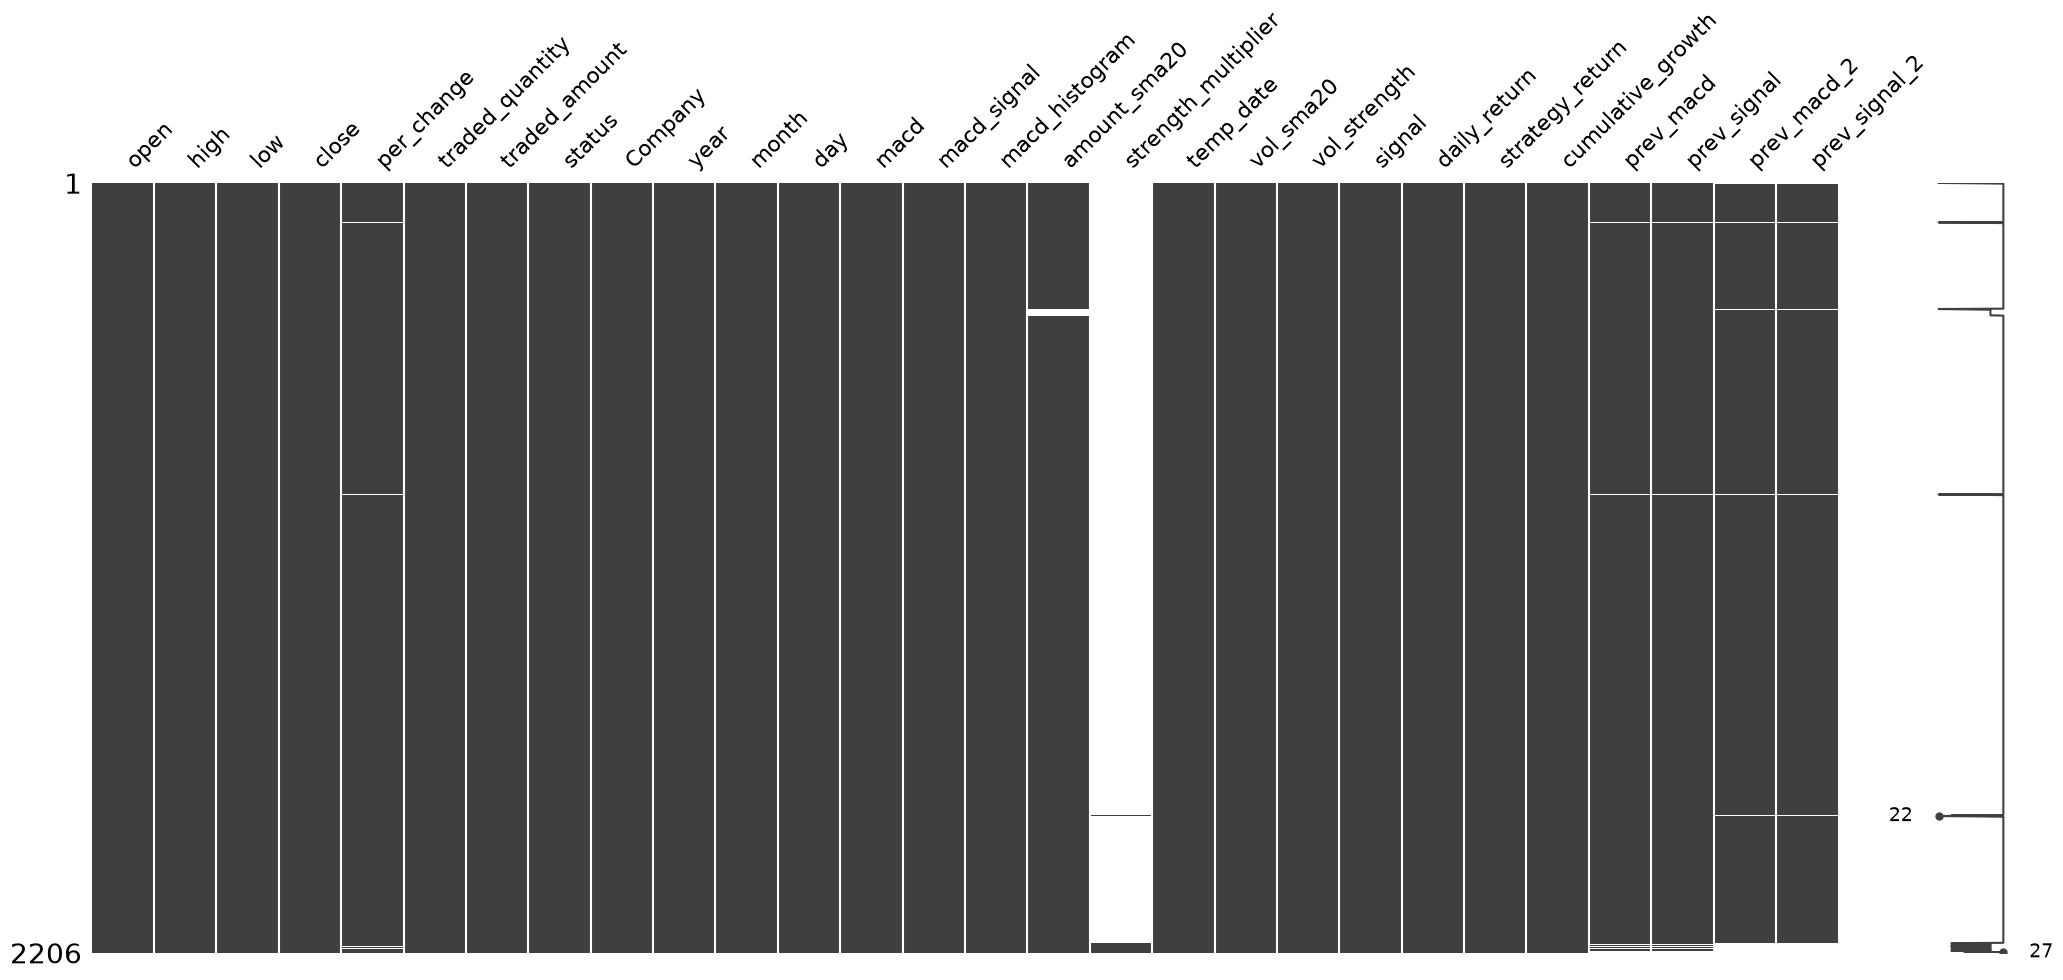

In [ ]:
ms.matrix(empty_rows)

## NEPSE COMPLETE LOGIC


In [34]:
# ------------------------------------------------------------------------------
# 1. SETUP & DATA CLEANING (Including NaN Handling)
# ------------------------------------------------------------------------------
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy['temp_date'])

# Drop rows where critical trading data contains NaN values
critical_columns = ['Company', 'temp_date', 'close', 'macd', 'macd_signal', 'macd_histogram', 'signal']
nepse_copy = nepse_copy.dropna(subset=critical_columns)

# Ensure data is sorted chronologically by Company and temp_date
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

## current balance

In [41]:
import os
import pandas as pd
import numpy as np
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# Ensure separate output folder exists
output_dir = "NEPSE_Trading_Reports"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------------------------
# 1. SETUP & DATA CLEANING (Including NaN Handling)
# ------------------------------------------------------------------------------
nepse_copy['temp_date'] = pd.to_datetime(nepse_copy['temp_date'])

# Drop rows where critical trading data contains NaN values
critical_columns = ['Company', 'temp_date', 'close', 'macd', 'macd_signal', 'macd_histogram', 'signal']
nepse_copy = nepse_copy.dropna(subset=critical_columns)

# Ensure nepse_copy is sorted chronologically by Company and temp_date
nepse_copy = nepse_copy.sort_values(by=['Company', 'temp_date']).reset_index(drop=True)

# NEPSE Trading Fee Functions (Zero Commissions / Pure Gross Calculations)
def calculate_buy_cost(quantity, price):
    total_cost = quantity * price
    fees = 0.0
    return round(total_cost, 2), round(fees, 2)

def calculate_sell_proceeds(quantity, price):
    net_proceeds = quantity * price
    fees = 0.0
    return round(net_proceeds, 2), round(fees, 2)

INITIAL_BUDGET = 200000.0
MIN_QUANTITY = 10
COMPANY_ALLOCATION_LIMIT = 20000.0  # Limits max spend per company to diversify across 10+ stocks

cash_balance = INITIAL_BUDGET
completed_transactions = []
active_positions = []

simulation_dates = pd.date_range(start="2015-01-01", end="2026-03-31", freq="B")

# ------------------------------------------------------------------------------
# 2. DAY-BY-DAY REACTIVE TRADING SIMULATION LOOP
# ------------------------------------------------------------------------------
for curr_date in simulation_dates:
    daily_data = nepse_copy[nepse_copy['temp_date'] == curr_date]
    date_str = curr_date.strftime('%Y-%m-%d')
    
    # Process Exits (Bearish MACD crossover or stop-loss <= -4%)
    remaining_open = []
    for pos in active_positions:
        comp_data = daily_data[daily_data['Company'] == pos['Company']]
        if len(comp_data) > 0:
            curr_row = comp_data.iloc[0]
            curr_price = float(curr_row['close'])
            curr_macd = float(curr_row['macd'])
            curr_signal = float(curr_row['macd_signal'])
            
            sell_proceeds, sell_fees = calculate_sell_proceeds(pos['buy_quantity'], curr_price)
            ret_pct = (sell_proceeds - pos['Total_amount_buyCost']) / pos['Total_amount_buyCost']
            
            is_bearish_crossover = curr_macd < curr_signal
            if is_bearish_crossover or ret_pct <= -0.04:
                cash_balance += sell_proceeds
                pnl = round(sell_proceeds - pos['Total_amount_buyCost'], 2)
                pnl_pct = round((pnl / pos['Total_amount_buyCost']) * 100, 2)
                
                completed_transactions.append({
                    'Company': pos['Company'],
                    'buy_date': pos['buy_date'],
                    'buy_quantity': pos['buy_quantity'],
                    'buy_rate': pos['buy_rate'],
                    'macd_on_buyDate': pos['macd_on_buyDate'],
                    'Total_amount_buyCost': pos['Total_amount_buyCost'],
                    'cash_balance_after_buy': pos['cash_balance_after_buy'],
                    'sell_date': date_str,
                    'sell_quantity': pos['buy_quantity'],
                    'sell_rate': curr_price,
                    'macd_on_sellingDate': round(curr_macd, 4),
                    'total_amount_recieved': sell_proceeds,
                    'profit/loss': pnl,
                    'profit/loss percentage respect to buy': pnl_pct,
                    'cash_balance_after_sell': round(cash_balance, 2)
                })
            else:
                remaining_open.append(pos)
        else:
            remaining_open.append(pos)
    active_positions = remaining_open

    # Process Buys: Strict Strategy -> Bullish Signal (1) AND MACD < 0 (Recovery from a dip)
    if cash_balance > MIN_QUANTITY * 20:
        buy_candidates = daily_data[(daily_data['signal'] == 1) & (daily_data['macd'] < 0)]
        held_companies = {pos['Company'] for pos in active_positions}
        buy_candidates = buy_candidates[~buy_candidates['Company'].isin(held_companies)]
        
        if len(buy_candidates) > 0:
            buy_candidates = buy_candidates.sort_values(by='macd_histogram', ascending=False)
            
            for _, cand in buy_candidates.iterrows():
                b_price = float(cand['close'])
                b_macd = round(float(cand['macd']), 4)
                comp_name = cand['Company']
                
                min_buy_cost, min_fees = calculate_buy_cost(MIN_QUANTITY, b_price)
                if cash_balance >= min_buy_cost:
                    # Diversified allocation capped at COMPANY_ALLOCATION_LIMIT per stock
                    max_spend = min(COMPANY_ALLOCATION_LIMIT, cash_balance)
                    raw_qty = int(max_spend // b_price)
                    buy_qty = max(MIN_QUANTITY, raw_qty)
                    
                    buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_price)
                    while buy_cost > cash_balance and buy_qty > MIN_QUANTITY:
                        buy_qty -= 1
                        buy_cost, buy_fees = calculate_buy_cost(buy_qty, b_price)
                        
                    if buy_cost <= cash_balance:
                        cash_balance -= buy_cost
                        active_positions.append({
                            'Company': comp_name,
                            'buy_date': date_str,
                            'buy_quantity': buy_qty,
                            'buy_rate': b_price,
                            'macd_on_buyDate': b_macd,
                            'Total_amount_buyCost': buy_cost,
                            'cash_balance_after_buy': round(cash_balance, 2)
                        })

# ------------------------------------------------------------------------------
# 3. TRACK OPEN / UNSOLD POSITIONS AT FINAL DATE (NO COMPULSORY SELL)
# ------------------------------------------------------------------------------
unsold_shares_value = 0.0
unsold_records = []
final_day_data = nepse_copy[nepse_copy['temp_date'] == simulation_dates[-1]]

for pos in active_positions:
    comp_final = final_day_data[final_day_data['Company'] == pos['Company']]
    if len(comp_final) > 0:
        fp = float(comp_final.iloc[0]['close'])
        f_macd = round(float(comp_final.iloc[0]['macd']), 4)
        val, _ = calculate_sell_proceeds(pos['buy_quantity'], fp)
        unsold_shares_value += val
        
        pnl = round(val - pos['Total_amount_buyCost'], 2)
        pnl_pct = round((pnl / pos['Total_amount_buyCost']) * 100, 2)
        
        unsold_records.append({
            'Company': pos['Company'],
            'buy_date': pos['buy_date'],
            'buy_quantity': pos['buy_quantity'],
            'buy_rate': pos['buy_rate'],
            'macd_on_buyDate': pos['macd_on_buyDate'],
            'Total_amount_buyCost': pos['Total_amount_buyCost'],
            'cash_balance_after_buy': pos['cash_balance_after_buy'],
            'current_rate': fp,
            'current_macd': f_macd,
            'estimated_market_value': val,
            'unrealized_profit/loss': pnl,
            'unrealized_profit/loss_pct': pnl_pct
        })

df_tx = pd.DataFrame(completed_transactions)
if len(df_tx) > 0:
    df_tx['buy_date_dt'] = pd.to_datetime(df_tx['buy_date'])
    df_tx = df_tx.sort_values(by='buy_date_dt').drop(columns=['buy_date_dt']).reset_index(drop=True)

df_unsold = pd.DataFrame(unsold_records)
if len(df_unsold) > 0:
    df_unsold['buy_date_dt'] = pd.to_datetime(df_unsold['buy_date'])
    df_unsold = df_unsold.sort_values(by='buy_date_dt').drop(columns=['buy_date_dt']).reset_index(drop=True)

num_trades = len(df_tx)
profitable_trades = len(df_tx[df_tx['profit/loss'] > 0]) if num_trades > 0 else 0
losing_trades = len(df_tx[df_tx['profit/loss'] <= 0]) if num_trades > 0 else 0
total_realized_pnl = round(df_tx['profit/loss'].sum(), 2) if num_trades > 0 else 0.0
final_portfolio_value = round(cash_balance + unsold_shares_value, 2)
net_capital_increase = round(final_portfolio_value - INITIAL_BUDGET, 2)
total_return_pct = round((net_capital_increase / INITIAL_BUDGET) * 100, 2)
capital_growth = round(final_portfolio_value / INITIAL_BUDGET, 2)

# Common styling variables
header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
title_font = Font(name="Calibri", size=15, bold=True, color="1F4E78")
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'), right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'), bottom=Side(style='thin', color='D9D9D9')
)

# ------------------------------------------------------------------------------
# 4. EXPORT MAIN RESULTS WORKBOOK
# ------------------------------------------------------------------------------
file_path = os.path.join(output_dir, "NEPSE_Results.xlsx")
wb = openpyxl.Workbook()

# Sheet 1: Transactions
ws_tx = wb.active
ws_tx.title = "Transactions"
ws_tx.views.sheetView[0].showGridLines = True


ws_tx.append([])

ws_tx.cell(row=1, column=1).font = title_font
ws_tx.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

tx_columns = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'cash_balance_after_buy', 'sell_date', 'sell_quantity', 
    'sell_rate', 'macd_on_sellingDate', 'total_amount_recieved', 'profit/loss', 
    'profit/loss percentage respect to buy', 'cash_balance_after_sell'
]

ws_tx.append(tx_columns)
for col_num in range(1, len(tx_columns) + 1):
    cell = ws_tx.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

if num_trades > 0:
    for r_idx, row in df_tx[tx_columns].iterrows():
        row_data = list(row.values)
        ws_tx.append(row_data)
        curr_row = 5 + r_idx
        for c_idx in range(1, len(row_data) + 1):
            cell = ws_tx.cell(row=curr_row, column=c_idx)
            cell.border = thin_border
            if c_idx in [4, 6, 7, 10, 12, 13, 15]:
                cell.number_format = 'NPR #,##0.00'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [3, 9]:
                cell.number_format = '#,##0'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [5, 11]:
                cell.number_format = '0.0000'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 14:
                cell.number_format = '0.00"%"'
                cell.alignment = Alignment(horizontal="right")
            else:
                cell.alignment = Alignment(horizontal="center")

ws_tx.row_dimensions[4].height = 28
for col in ws_tx.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_tx.column_dimensions[col_letter].width = max(max_len + 3, 14)

# Sheet 2: Unsold Positions
ws_open = wb.create_sheet(title="Unsold Positions")
ws_open.views.sheetView[0].showGridLines = True


ws_open.cell(row=1, column=1).font = title_font
ws_open.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

open_cols = [
    'Company', 'buy_date', 'buy_quantity', 'buy_rate', 'macd_on_buyDate', 
    'Total_amount_buyCost', 'cash_balance_after_buy', 'current_rate', 'current_macd', 
    'estimated_market_value', 'unrealized_profit/loss', 'unrealized_profit/loss_pct'
]

ws_open.append(open_cols)
for col_num in range(1, len(open_cols) + 1):
    cell = ws_open.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

if len(unsold_records) > 0:
    for r_idx, row in df_unsold[open_cols].iterrows():
        row_data = list(row.values)
        ws_open.append(row_data)
        curr_row = 5 + r_idx
        for c_idx in range(1, len(row_data) + 1):
            cell = ws_open.cell(row=curr_row, column=c_idx)
            cell.border = thin_border
            if c_idx in [4, 6, 7, 8, 10, 11]:
                cell.number_format = 'NPR #,##0.00'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 3:
                cell.number_format = '#,##0'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [5, 9]:
                cell.number_format = '0.0000'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 12:
                cell.number_format = '0.00"%"'
                cell.alignment = Alignment(horizontal="right")
            else:
                cell.alignment = Alignment(horizontal="center")

ws_open.row_dimensions[4].height = 28
for col in ws_open.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_open.column_dimensions[col_letter].width = max(max_len + 3, 14)

# Sheet 3: Summary
ws_sum = wb.create_sheet(title="Summary")
ws_sum.views.sheetView[0].showGridLines = True


ws_sum.cell(row=1, column=1).font = title_font

summary_data = [
    ("Initial budget", INITIAL_BUDGET, "NPR #,##0.00"),
    ("Total number of completed trades", num_trades, "#,##0"),
    ("Total number of profitable and losing trades", f"{profitable_trades} Profitable / {losing_trades} Losing", "@"),
    ("Total realized profit or loss", total_realized_pnl, "NPR #,##0.00"),
    ("Final available cash balance", cash_balance, "NPR #,##0.00"),
    ("Value of open unsold shares at final price", unsold_shares_value, "NPR #,##0.00"),
    ("Final total portfolio value", final_portfolio_value, "NPR #,##0.00"),
    ("Net capital increase in NPR", net_capital_increase, "NPR #,##0.00"),
    ("Total return percentage relative to initial budget", total_return_pct / 100, "0.00%"),
    ("Final capital growth compared with initial 200k", capital_growth, '0.00"x"')
]

ws_sum.append(["Performance Metric", "Strategy Value"])
ws_sum.cell(row=3, column=1).fill = header_fill
ws_sum.cell(row=3, column=1).font = header_font
ws_sum.cell(row=3, column=2).fill = header_fill
ws_sum.cell(row=3, column=2).font = header_font

for idx, (metric, val, num_fmt) in enumerate(summary_data, start=4):
    ws_sum.append([metric, val])
    cell_lbl = ws_sum.cell(row=idx, column=1)
    cell_val = ws_sum.cell(row=idx, column=2)
    cell_lbl.border = thin_border
    cell_val.border = thin_border
    cell_lbl.font = Font(name="Calibri", size=11, bold=True)
    cell_val.font = Font(name="Calibri", size=11, bold=True)
    if num_fmt != "@":
        cell_val.number_format = num_fmt
        cell_val.alignment = Alignment(horizontal="right")
    else:
        cell_val.alignment = Alignment(horizontal="center")

ws_sum.column_dimensions['A'].width = 50
ws_sum.column_dimensions['B'].width = 30
wb.save(file_path)

# ------------------------------------------------------------------------------
# 5. EXPORT DEDICATED SHEET: nepse-automated-stoke.xlsx
# ------------------------------------------------------------------------------
automated_file_path = os.path.join(output_dir, "nepse-automated-stoke.xlsx")
wb_auto = openpyxl.Workbook()
ws_auto = wb_auto.active
ws_auto.title = "Automated Trades"
ws_auto.views.sheetView[0].showGridLines = True

ws_auto.append([])
ws_auto.cell(row=1, column=1).font = title_font
ws_auto.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

ws_auto.append(tx_columns)
for col_num in range(1, len(tx_columns) + 1):
    cell = ws_auto.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

if num_trades > 0:
    for r_idx, row in df_tx[tx_columns].iterrows():
        row_data = list(row.values)
        ws_auto.append(row_data)
        curr_row = 5 + r_idx
        for c_idx in range(1, len(row_data) + 1):
            cell = ws_auto.cell(row=curr_row, column=c_idx)
            cell.border = thin_border
            if c_idx in [4, 6, 7, 10, 12, 13, 15]:
                cell.number_format = 'NPR #,##0.00'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [3, 9]:
                cell.number_format = '#,##0'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [5, 11]:
                cell.number_format = '0.0000'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 14:
                cell.number_format = '0.00"%"'
                cell.alignment = Alignment(horizontal="right")
            else:
                cell.alignment = Alignment(horizontal="center")

ws_auto.row_dimensions[4].height = 28
for col in ws_auto.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_auto.column_dimensions[col_letter].width = max(max_len + 3, 14)

wb_auto.save(automated_file_path)

# ------------------------------------------------------------------------------
# 6. EXPORT DEDICATED COMPANY-WISE SUMMARY WORKBOOK: NEPSE_Company_Wise_Report.xlsx
# ------------------------------------------------------------------------------
company_report_path = os.path.join(output_dir, "Company_Wise_Report.xlsx")
wb_comp_rep = openpyxl.Workbook()
ws_comp_rep = wb_comp_rep.active
ws_comp_rep.title = "Company Wise Summary"
ws_comp_rep.views.sheetView[0].showGridLines = True


ws_comp_rep.cell(row=1, column=1).font = title_font
ws_comp_rep.cell(row=2, column=1).font = Font(name="Calibri", size=11, italic=True, color="595959")

comp_rep_columns = [
    'company', 'buy_quantities', 'traded_amount', 'sell_quantities', 
    'received_amount', '%gain/loss', 'available_quantity', 'current_balance'
]

ws_comp_rep.append(comp_rep_columns)
for col_num in range(1, len(comp_rep_columns) + 1):
    cell = ws_comp_rep.cell(row=4, column=col_num)
    cell.fill = header_fill
    cell.font = header_font
    cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

all_companies = set(df_tx['Company'].unique() if len(df_tx) > 0 else []).union(
    set(df_unsold['Company'].unique() if len(df_unsold) > 0 else [])
)

company_summary_records = []
for comp in sorted(all_companies):
    comp_tx = df_tx[df_tx['Company'] == comp] if len(df_tx) > 0 else pd.DataFrame()
    comp_unsold = df_unsold[df_unsold['Company'] == comp] if len(df_unsold) > 0 else pd.DataFrame()
    
    buy_qty = (comp_tx['buy_quantity'].sum() if len(comp_tx) > 0 else 0) + (comp_unsold['buy_quantity'].sum() if len(comp_unsold) > 0 else 0)
    traded_amt = (comp_tx['Total_amount_buyCost'].sum() if len(comp_tx) > 0 else 0.0) + (comp_unsold['Total_amount_buyCost'].sum() if len(comp_unsold) > 0 else 0.0)
    sell_qty = comp_tx['sell_quantity'].sum() if len(comp_tx) > 0 else 0
    rec_amt = comp_tx['total_amount_recieved'].sum() if len(comp_tx) > 0 else 0.0
    avail_qty = comp_unsold['buy_quantity'].sum() if len(comp_unsold) > 0 else 0
    
    unsold_val = comp_unsold['estimated_market_value'].sum() if len(comp_unsold) > 0 else 0.0
    total_val = rec_amt + unsold_val
    gain_loss_pct = ((total_val - traded_amt) / traded_amt * 100) if traded_amt > 0 else 0.0
    
    cash_vals = []
    if len(comp_tx) > 0:
        cash_vals.extend(comp_tx['cash_balance_after_sell'].tolist())
    if len(comp_unsold) > 0:
        cash_vals.extend(comp_unsold['cash_balance_after_buy'].tolist())
    curr_bal = cash_vals[-1] if cash_vals else cash_balance
    
    company_summary_records.append({
        'company': comp,
        'buy_quantities': int(buy_qty),
        'traded_amount': round(traded_amt, 2),
        'sell_quantities': int(sell_qty),
        'received_amount': round(rec_amt, 2),
        '%gain/loss': round(gain_loss_pct, 2),
        'available_quantity': int(avail_qty),
        'current_balance': round(curr_bal, 2)
    })

df_comp_rep = pd.DataFrame(company_summary_records)
if len(df_comp_rep) > 0:
    df_comp_rep = df_comp_rep.sort_values(by='traded_amount', ascending=False).reset_index(drop=True)
    for r_idx, row in df_comp_rep[comp_rep_columns].iterrows():
        row_data = list(row.values)
        ws_comp_rep.append(row_data)
        curr_row = 5 + r_idx
        for c_idx in range(1, len(row_data) + 1):
            cell = ws_comp_rep.cell(row=curr_row, column=c_idx)
            cell.border = thin_border
            if c_idx in [3, 5, 8]:
                cell.number_format = 'NPR #,##0.00'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx in [2, 4, 7]:
                cell.number_format = '#,##0'
                cell.alignment = Alignment(horizontal="right")
            elif c_idx == 6:
                cell.number_format = '0.00"%"'
                cell.alignment = Alignment(horizontal="right")
            else:
                cell.alignment = Alignment(horizontal="center")

ws_comp_rep.row_dimensions[4].height = 28
for col in ws_comp_rep.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws_comp_rep.column_dimensions[col_letter].width = max(max_len + 3, 16)

wb_comp_rep.save(company_report_path)

print("Simulation complete. Company-wise report file 'NEPSE_Company_Wise_Report.xlsx' created successfully.")

Simulation complete. Company-wise report file 'NEPSE_Company_Wise_Report.xlsx' created successfully.
